<div style="border-left:7px solid #F97316;padding:14px 0 14px 22px;background:#FFFFFF;">
  <p style="font-size:14px;font-weight:700;letter-spacing:1.3px;margin:0 0 8px;"><font color="#6A0DAD"><b>DATA SCIENCE COMPETITION FIK FAIR 2026</b></font></p>
  <h1><font color="#6A0DAD"><b>Prediksi Anonymous Competition Score (ACS)</b></font></h1>
  <p style="font-size:18px;font-weight:600;margin:0;"><font color="#F28C28"><b>Dari memahami data hingga menghasilkan prediksi akhir</b></font></p>
  <p style="font-size:15px;margin:10px 0 0;"><font color="#344B55">24 fitur resmi · Metode CRISP-DM · Validasi 5-fold</font></p>
</div>

Notebook ini menjelaskan cara kami memprediksi **<font color="#6A0DAD">Anonymous Competition Score (ACS)</font>** menggunakan data resmi kompetisi. Alurnya mengikuti enam tahap CRISP-DM, mulai dari memahami masalah, memeriksa data, membangun model, hingga mengecek hasil prediksi.

Di setiap bagian, kami menjelaskan apa yang dikerjakan, mengapa dilakukan, dan bagaimana membaca hasilnya. Tabel serta grafik berasal dari kode yang dijalankan; gambar pembuka hanya ilustrasi. Hasil eksekusi sudah tersimpan agar notebook tetap bisa dibaca tanpa menjalankan ulang seluruh proses.

# <font color="#6A0DAD"><b>Studi Kasus dan Tujuan Analisis</b></font>

## <font color="#F28C28"><b>Studi kasus: memprediksi biaya hidup relatif</b></font>

Biaya hidup relatif dapat berbeda antarwilayah. Pada kompetisi ini, perbedaan tersebut digambarkan melalui **<font color="#6A0DAD">Anonymous Competition Score (ACS)</font>**. Berdasarkan [Case Release resmi](ketentuan/Case%20Release_DSC%20FIK%20FAIR%202026.pdf), semakin tinggi ACS, semakin tinggi pula biaya hidup relatif yang diwakilinya.

Data resmi yang digunakan terdiri dari **<font color="#F28C28">382 record train</font>** (memiliki nilai ACS) dan **<font color="#F28C28">96 record test</font>** (nilai ACS belum diketahui). Setiap record mempunyai **24 fitur numerik** yang sudah disamarkan. Karena identitas wilayah dan arti asli fiturnya tidak diberikan, analisis ini fokus pada pola data dan ketepatan prediksi, bukan menebak nama wilayah.

**<font color="#6A0DAD">Tugas utama:</font>** mempelajari hubungan antara 24 fitur dan ACS pada data train, lalu menghasilkan satu prediksi ACS untuk setiap record test. **<font color="#F28C28">ACS bukan nilai rupiah</font>**, melainkan skor relatif tanpa satuan uang.

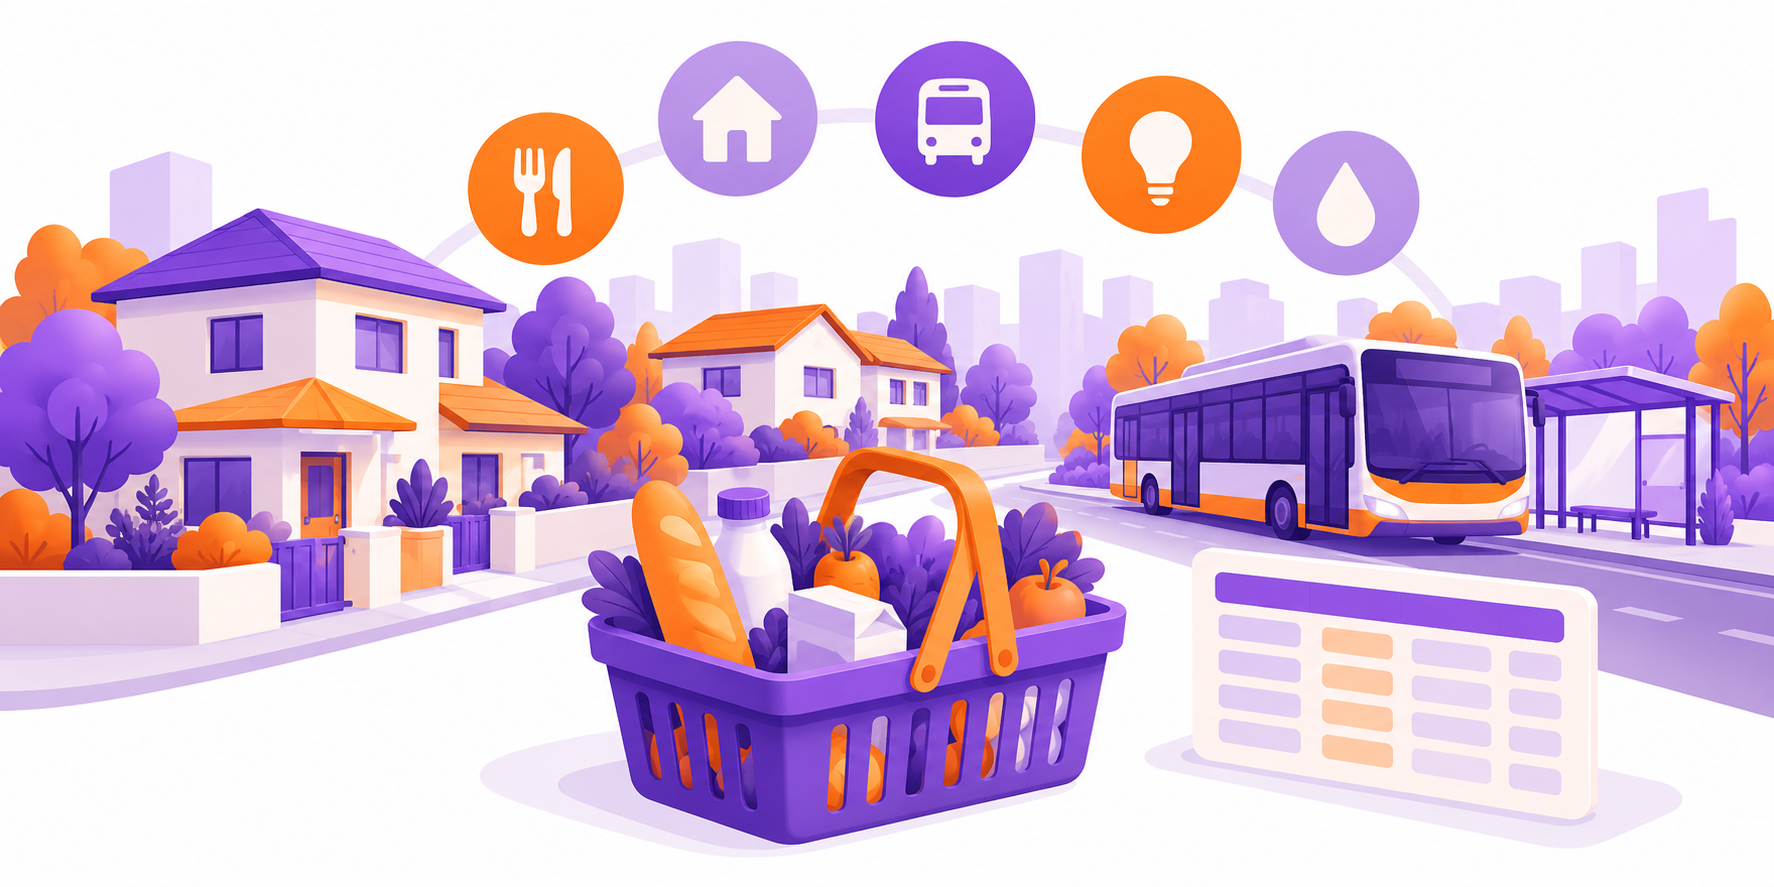

*Gambar 1. Ilustrasi umum biaya hidup relatif (dibuat dengan AI). Gambar ini bukan data kompetisi dan tidak digunakan dalam pemodelan.*

## <font color="#F28C28"><b>Tujuan analisis</b></font>

Kami ingin menjawab enam hal utama:

1. **<font color="#6A0DAD">Kualitas data:</font>** Apakah kolom, nilai, dan ID sudah sesuai?
2. **<font color="#6A0DAD">Pola data:</font>** Bagaimana sebaran ACS dan hubungan antarfitur?
3. **<font color="#6A0DAD">Persiapan:</font>** Bagaimana fitur dipisahkan dari ID dan target, lalu ditransformasi?
4. **<font color="#6A0DAD">Pemodelan:</font>** Model mana yang memberikan kesalahan prediksi paling kecil?
5. **<font color="#6A0DAD">Evaluasi:</font>** Di kelompok ACS mana model masih sering meleset?
6. **<font color="#6A0DAD">Hasil akhir:</font>** Apakah seluruh prediksi test sesuai format submission dan bisa dibuat ulang?

## <font color="#F28C28"><b>Batasan analisis</b></font>

Hanya `feature_01` hingga `feature_24` yang menjadi prediktor. `record_id` dipakai untuk mencocokkan hasil, **<font color="#F28C28">bukan sebagai fitur</font>**. Karena nama dan makna asli fitur tidak diketahui, hubungan statistik tidak dianggap sebagai hubungan sebab-akibat.

Model belajar dari **target train resmi**. Pada beberapa tahap PCA, fitur validasi dan test boleh digunakan **tanpa label** sesuai metode pada pipeline. Target validasi tetap disembunyikan saat pelatihan setiap fold, dan target test tidak digunakan. Hasil validasi lokal juga **bukan skor private leaderboard**.

# <font color="#6A0DAD"><b>Tahapan Analisis dengan CRISP-DM</b></font>

Kami memakai **<font color="#6A0DAD">CRISP-DM</font>** agar urutan pekerjaan mudah dipahami dan diperiksa. Prosesnya terdiri dari enam tahap:

<div style="border-left:4px solid #F97316;background:#FFF7ED;padding:12px 16px;line-height:1.9;font-weight:600;">
<span style="color:#F28C28;">Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment</span>
</div>

| Tahap | Apa yang dilakukan? | Hasil utama |
|---|---|---|
| **<font color="#6A0DAD">1. Memahami masalah</font>** | Menentukan target, metrik, dan aturan data | Tujuan prediksi ACS |
| **<font color="#6A0DAD">2. Memahami data</font>** | Mengecek data serta membuat grafik eksplorasi | Audit dan pola data |
| **<font color="#6A0DAD">3. Menyiapkan data</font>** | Memisahkan fitur, ID, dan target; menjelaskan transformasi | Matriks siap diproses |
| **<font color="#6A0DAD">4. Membangun model</font>** | Membandingkan beberapa model dengan validasi 5-fold | Prediksi out-of-fold |
| **<font color="#6A0DAD">5. Mengevaluasi</font>** | Membandingkan kesalahan dan mencari kelemahan model | RMSE, MAE, dan analisis error |
| **<font color="#6A0DAD">6. Menghasilkan prediksi</font>** | Melatih model dengan seluruh train dan memeriksa submission | 96 prediksi test terverifikasi |

**<font color="#F28C28">Aturan penting:</font>** pada validasi, model tidak mempelajari *target* record yang sedang diuji. Setelah evaluasi, barulah seluruh data train berlabel dipakai untuk membuat prediksi test. Istilah *deployment* di sini berarti menyiapkan hasil kompetisi, bukan menjalankan sistem nyata.

# <font color="#6A0DAD"><b>01 · Business Understanding</b></font>

## <font color="#F28C28"><b>1.1 · Target dan ukuran keberhasilan</b></font>

Masalah ini termasuk **<font color="#6A0DAD">regresi</font>**, yaitu memprediksi angka. Angka yang diprediksi adalah ACS, skor biaya hidup relatif yang telah dianonimkan. Penjelasan target mengacu pada [Case Release](ketentuan/Case%20Release_DSC%20FIK%20FAIR%202026.pdf) dan [kamus data resmi](data/data_dictionary.csv).

Kompetisi menggunakan **<font color="#F28C28">RMSE (Root Mean Squared Error)</font>** sebagai ukuran utama. Sederhananya, RMSE mengukur seberapa jauh prediksi dari nilai sebenarnya. **<font color="#F28C28">Semakin kecil RMSE, semakin baik.</font>** Kesalahan yang sangat besar akan lebih berpengaruh pada RMSE. Kami juga melihat **MAE**, yaitu rata-rata besar selisih prediksi, sebagai informasi tambahan.

Data test dibagi menjadi 29 record untuk *public leaderboard* dan 67 untuk *private leaderboard*. Nilai validasi di notebook hanya perkiraan kemampuan model, **<font color="#F28C28">bukan hasil private leaderboard</font>**.

## <font color="#F28C28"><b>1.2 · Aturan penggunaan data</b></font>

Model hanya menggunakan 24 fitur resmi dan target dari train. `record_id` hanya untuk identitas hasil; urutan baris tidak digunakan untuk memprediksi.

## <font color="#F28C28"><b>Cara membaca dan menjalankan notebook</b></font>

Notebook dibaca **dari atas ke bawah**. Setiap penjelasan diikuti kode,
tabel, atau grafik yang sesuai. Seluruh kode model asli sudah **ditanam di
dalam notebook ini**, sehingga tidak perlu mengunggah `pipeline.py` secara
terpisah.

<div style="border-left:4px solid #6D28D9;background:#F5F3FF;padding:12px 16px;line-height:1.75;">
<strong style="color:#6A0DAD;">Cara menjalankan di Google Colab</strong><br>
1. Unggah notebook ini ke Colab.<br>
2. Pilih <strong>Runtime → Run all</strong>.<br>
3. Jika diminta, unggah <code>train.csv</code> dan <code>test.csv</code> resmi.
   <code>data_dictionary.csv</code> dan <code>submission_template.csv</code>
   boleh ikut diunggah untuk dokumentasi dan pemeriksaan tambahan.<br>
4. Tunggu evaluasi lima fold dan pelatihan akhir selesai. Pada eksekusi
   pertama, TabICL akan mengunduh checkpoint publik yang digunakan model.<br>
5. Berkas <code>submission.csv</code> akan dibuat, diperiksa, dan otomatis
   ditawarkan untuk diunduh pada bagian terakhir.
</div>

Sel instalasi hanya memasang pustaka yang belum tersedia. Sel pipeline
memuat sumber model yang sama dengan proyek kompetisi dan mencatat hash
SHA-256-nya. Dengan demikian, notebook tetap dapat diaudit dan dijalankan
sebagai satu berkas, selama internet tersedia untuk instalasi/checkpoint.

**<font color="#F28C28">Catatan waktu:</font>** validasi lima fold melatih TabICL berulang kali. Pada CPU
Colab proses ini dapat memerlukan beberapa menit. Jangan menghentikan sel
hanya karena tidak langsung menghasilkan output.

### <font color="#F28C28"><b>1.3 · Menyiapkan Google Colab dan dependensi</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Mendeteksi apakah notebook berjalan di Google Colab.
2. Memastikan Python menggunakan versi yang sesuai.
3. Memasang `tabicl` dan `threadpoolctl` hanya jika belum tersedia.
4. Meminta unggahan `train.csv` dan `test.csv` apabila keduanya belum ditemukan.

**<font color="#F28C28">Hasil yang dilihat:</font>** status lingkungan, instalasi dependency, dan lokasi file input.

**<font color="#F28C28">Catatan:</font>** instalasi dan unduhan checkpoint memerlukan internet. Data yang
diunggah hanya digunakan di sesi runtime Colab aktif.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

IN_COLAB = importlib.util.find_spec('google.colab') is not None
if sys.version_info < (3, 10):
    raise RuntimeError('Notebook memerlukan Python 3.10 atau lebih baru.')

dependency_map = {
    'tabicl': 'tabicl==2.2.0',
    'threadpoolctl': 'threadpoolctl>=3.6.0',
}
missing_packages = [package for module, package in dependency_map.items()
                    if importlib.util.find_spec(module) is None]
if missing_packages:
    print('Memasang dependency:', ', '.join(missing_packages))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing_packages])
    importlib.invalidate_caches()
else:
    print('Dependency model sudah tersedia.')

candidate_roots = [Path.cwd(), Path('/content')]
input_ready = any(
    ((root / 'train.csv').is_file() and (root / 'test.csv').is_file()) or
    ((root / 'data/train.csv').is_file() and (root / 'data/test.csv').is_file())
    for root in candidate_roots
)
if IN_COLAB and not input_ready:
    from google.colab import files as colab_files
    print('Unggah train.csv dan test.csv resmi. File kamus/template boleh ikut dipilih.')
    uploaded = colab_files.upload()
    if not {'train.csv', 'test.csv'}.issubset(uploaded):
        raise FileNotFoundError('Unggahan harus memuat train.csv dan test.csv.')

print('Lingkungan:', 'Google Colab' if IN_COLAB else 'Jupyter/VS Code lokal')
print('Python:', sys.version.split()[0])

Dependency model sudah tersedia.
Lingkungan: Jupyter/VS Code lokal
Python: 3.11.7


### <font color="#F28C28"><b>1.4 · Memuat pipeline model yang tertanam</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Membaca sumber pipeline yang sudah disimpan di dalam sel notebook.
2. Menghitung **SHA-256** agar versi kode model dapat ditelusuri.
3. Menjalankan sumber tersebut di namespace terpisah tanpa menulis `pipeline.py`.
4. Mengambil konstanta, fungsi validasi, evaluasi, dan prediksi yang dipakai sel berikutnya.

**<font color="#F28C28">Hasil yang dilihat:</font>** konfirmasi bahwa pipeline siap serta fingerprint sumbernya.

**<font color="#F28C28">Catatan:</font>** kode ini bukan model pengganti. Isinya berasal dari pipeline
kompetisi yang sama; penyematan dilakukan agar notebook benar-benar mandiri
ketika dijalankan di Colab.

In [2]:
import hashlib

PIPELINE_SOURCE = r'''"""Reproducible feature-only ACS regression pipeline.

The predictors are the 24 official anonymized features. Identifiers and row
positions never enter a model. Unsupervised PCA may use the query features and
an optional unlabeled reference; every supervised fit uses training labels only.

TabICL is an external pretrained general-purpose model, supplied by the `tabicl`
package. Its checkpoint is explicit below; it is not used for entity matching
or retrieving competition targets.
Official checkpoint source: https://huggingface.co/jingang/TabICL (the repository
used by the installed TabICLRegressor checkpoint downloader).
"""

from __future__ import annotations

import argparse
from contextlib import contextmanager
from pathlib import Path
from typing import Iterator

import numpy as np
import pandas as pd
import torch
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from tabicl import TabICLRegressor
from threadpoolctl import threadpool_limits


FEATURE_NAMES = tuple(f"feature_{i:02d}" for i in range(1, 25))
MODEL_SEED = 2026
VALIDATION_SEED = 314159
THREADS = 2
CHECKPOINT = "tabicl-regressor-v2-20260212.ckpt"
SVR_WEIGHTS = {
    "weighted_svr": 0.18,
    "correlation_svr": 0.20,
    "pca12_svr": 0.27,
    "pca16_svr": 0.18,
    "pca20_svr": 0.17,
}
FINAL_WEIGHTS = {"svr_ensemble": 0.40, "tabicl": 0.60}
EVALUATION_MODELS = (
    "mean_baseline",
    "ridge",
    "extra_trees",
    "scaled_svr",
    "svr_ensemble",
    "tabicl",
    "final_ensemble",
)
PACKAGE_ROOT = Path(__file__).resolve().parents[1]


class CorrelationMetric(BaseEstimator, TransformerMixin):
    """Learn feature-distance weights using only the fitted training targets."""

    def __init__(self, floor: float = 0.6, power: float = 2.0):
        self.floor = floor
        self.power = power

    def fit(self, X, y):
        correlations = np.array(
            [abs(np.corrcoef(X[:, j], y)[0, 1]) for j in range(X.shape[1])]
        )
        weights = (correlations + self.floor) ** self.power
        self.weight_ = weights / np.mean(weights)
        return self

    def transform(self, X):
        return np.asarray(X) * self.weight_


@contextmanager
def _runtime_limits() -> Iterator[None]:
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(THREADS)
    try:
        with threadpool_limits(limits=THREADS):
            yield
    finally:
        torch.set_num_threads(previous_threads)


def validate_inputs(train: pd.DataFrame, test: pd.DataFrame) -> list[str]:
    """Validate the official schema before extracting the feature matrix."""
    expected_train = ["record_id", *FEATURE_NAMES, "target"]
    expected_test = ["record_id", *FEATURE_NAMES]
    if list(train.columns) != expected_train:
        raise ValueError(f"train columns must be {expected_train}")
    if list(test.columns) != expected_test:
        raise ValueError(f"test columns must be {expected_test}")
    if train.empty or test.empty:
        raise ValueError("train and test must contain records")
    if train.isna().any().any() or test.isna().any().any():
        raise ValueError("Missing values are not permitted")
    if train.record_id.astype(str).str.strip().eq("").any() or test.record_id.astype(str).str.strip().eq("").any():
        raise ValueError("record_id values must not be blank")
    if train.record_id.duplicated().any() or test.record_id.duplicated().any():
        raise ValueError("record_id values must be unique within each file")
    if set(train.record_id).intersection(test.record_id):
        raise ValueError("Train and test IDs must be disjoint")
    for name, frame, columns in (
        ("train", train, [*FEATURE_NAMES, "target"]),
        ("test", test, list(FEATURE_NAMES)),
    ):
        if not all(pd.api.types.is_numeric_dtype(frame[col]) for col in columns):
            raise ValueError(f"All {name} features/targets must be numeric")
        if not np.isfinite(frame[columns].to_numpy(dtype=float)).all():
            raise ValueError(f"All {name} features/targets must be finite")
    return list(FEATURE_NAMES)


def validate_submission(submission: pd.DataFrame, test: pd.DataFrame) -> None:
    """Validate exactly two columns, 96 unique official IDs and finite values."""
    if list(submission.columns) != ["record_id", "prediction"]:
        raise ValueError("Submission schema must be record_id,prediction")
    if len(test) != 96 or len(submission) != 96:
        raise ValueError("Official submissions must contain exactly 96 records")
    if submission.record_id.isna().any() or submission.record_id.duplicated().any():
        raise ValueError("Submission IDs must be non-missing and unique")
    if submission.record_id.astype(str).str.strip().eq("").any():
        raise ValueError("Submission IDs must not be blank")
    if set(submission.record_id) != set(test.record_id):
        raise ValueError("Submission IDs must match test.csv exactly")
    if not pd.api.types.is_numeric_dtype(submission.prediction):
        raise ValueError("Predictions must be numeric")
    if not np.isfinite(submission.prediction.to_numpy(dtype=float)).all():
        raise ValueError("Predictions must be finite")


def _prepare_arrays(X, y=None, X_query=None, unlabeled_reference=None):
    if isinstance(X, pd.DataFrame):
        if not isinstance(y, pd.DataFrame) or X_query is not None:
            raise TypeError("For DataFrames, call predict_components(train, test)")
        train, test = X, y
        features = validate_inputs(train, test)
        X = train[features].to_numpy(dtype=float)
        y = train.target.to_numpy(dtype=float)
        X_query = test[features].to_numpy(dtype=float)
    else:
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_query = np.asarray(X_query, dtype=float)
    if X.ndim != 2 or X.shape[1] != 24 or len(X) == 0:
        raise ValueError("X must contain exactly 24 official feature columns")
    if X_query.ndim != 2 or X_query.shape[1] != 24 or len(X_query) == 0:
        raise ValueError("X_query must contain exactly 24 official feature columns")
    if y.ndim != 1 or len(y) != len(X):
        raise ValueError("y must be a one-dimensional training target")
    reference = None
    if unlabeled_reference is not None:
        if isinstance(unlabeled_reference, pd.DataFrame):
            reference = unlabeled_reference[list(FEATURE_NAMES)].to_numpy(dtype=float)
        else:
            reference = np.asarray(unlabeled_reference, dtype=float)
        if reference.ndim != 2 or reference.shape[1] != 24:
            raise ValueError("unlabeled_reference must contain 24 features")
    arrays = [X, y, X_query] + ([] if reference is None else [reference])
    if not all(np.isfinite(array).all() for array in arrays):
        raise ValueError("All model inputs must be finite")
    return X, y, X_query, reference


def _pca_prediction(X, y, X_query, n_components, c, gamma, reference=None):
    # No labels from query/reference are available or passed to these transforms.
    parts = [X, X_query] + ([] if reference is None else [reference])
    combined = np.vstack(parts)
    embedded = StandardScaler().fit_transform(combined)
    embedded = PCA(
        n_components=n_components, whiten=True, random_state=MODEL_SEED
    ).fit_transform(embedded)
    embedded = StandardScaler().fit_transform(embedded)
    fitted = SVR(C=c, gamma=gamma, epsilon=0.1).fit(embedded[: len(X)], y)
    return fitted.predict(embedded[len(X) : len(X) + len(X_query)])


def predict_components(X, y=None, X_query=None, unlabeled_reference=None):
    """Return model components from arrays, or from (train, test) DataFrames.

    In cross-validation, supply the official test features as reference and the
    held-out features as X_query. Their labels remain excluded from every fit.
    At final inference, the test is already X_query; omit the extra reference.
    """
    X, y, X_query, reference = _prepare_arrays(X, y, X_query, unlabeled_reference)
    predictions = {}
    with _runtime_limits():
        weighted = make_pipeline(
            StandardScaler(), SVR(C=100, gamma=0.08, epsilon=0.1)
        )
        weighted.fit(X, y, svr__sample_weight=np.where(y >= 75.0, 1.5, 1.0))
        predictions["weighted_svr"] = weighted.predict(X_query)
        correlation = make_pipeline(
            StandardScaler(),
            CorrelationMetric(floor=0.6, power=2.0),
            SVR(C=100, gamma=0.08, epsilon=0.1),
        )
        predictions["correlation_svr"] = correlation.fit(X, y).predict(X_query)
        for key, k, c, gamma in (
            ("pca12_svr", 12, 100, "scale"),
            ("pca16_svr", 16, 300, 0.08),
            ("pca20_svr", 20, 100, 0.04),
        ):
            predictions[key] = _pca_prediction(X, y, X_query, k, c, gamma, reference)
        predictions["svr_ensemble"] = sum(
            weight * predictions[name] for name, weight in SVR_WEIGHTS.items()
        )
        tabicl = TabICLRegressor(
            n_estimators=16,
            device="cpu",
            n_jobs=THREADS,
            random_state=MODEL_SEED,
            verbose=False,
            checkpoint_version=CHECKPOINT,
        )
        predictions["tabicl"] = np.asarray(tabicl.fit(X, y).predict(X_query), dtype=float)
        predictions["final_ensemble"] = sum(
            weight * predictions[name] for name, weight in FINAL_WEIGHTS.items()
        )
    if not all(np.isfinite(prediction).all() for prediction in predictions.values()):
        raise RuntimeError("A model produced a non-finite prediction")
    return predictions


def predict_final(X, y=None, X_query=None, unlabeled_reference=None) -> np.ndarray:
    """Predict the fixed final ensemble; returns one value per query record."""
    return predict_components(X, y, X_query, unlabeled_reference)["final_ensemble"]


def evaluate_models(train, test, seed=VALIDATION_SEED, folds=5):
    """Run actual shuffled cross-validation for the packaged models.

    PCA sees fold-training features, held-out query features, and the official
    unlabeled test features. Targets for every estimator and supervised distance
    metric come exclusively from the training portion of each fold.
    """
    features = validate_inputs(train, test)
    if not isinstance(folds, int) or not 2 <= folds <= len(train):
        raise ValueError("folds must be an integer between 2 and the training size")
    X, y = train[features].to_numpy(float), train.target.to_numpy(float)
    reference = test[features].to_numpy(float)
    oof = {name: np.empty(len(y), dtype=float) for name in EVALUATION_MODELS}
    fold_rows = []
    splitter = KFold(n_splits=folds, shuffle=True, random_state=seed)
    for fold, (tr, va) in enumerate(splitter.split(X), 1):
        components = predict_components(X[tr], y[tr], X[va], reference)
        baselines = {
            "mean_baseline": DummyRegressor(strategy="mean"),
            "ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
            "extra_trees": ExtraTreesRegressor(
                n_estimators=400, min_samples_leaf=2,
                random_state=MODEL_SEED, n_jobs=THREADS,
            ),
            "scaled_svr": make_pipeline(
                StandardScaler(), SVR(C=100, gamma=0.08, epsilon=0.1)
            ),
        }
        with _runtime_limits():
            fold_predictions = {
                name: np.asarray(model.fit(X[tr], y[tr]).predict(X[va]), dtype=float)
                for name, model in baselines.items()
            }
        fold_predictions.update({name: components[name] for name in EVALUATION_MODELS if name not in baselines})
        for name in EVALUATION_MODELS:
            prediction = fold_predictions[name]
            oof[name][va] = prediction
            fold_rows.append({
                "fold": fold, "model": name,
                "rmse": float(mean_squared_error(y[va], prediction) ** 0.5),
                "mae": float(mean_absolute_error(y[va], prediction)),
                "n_train": len(tr), "n_validation": len(va),
            })
        print(f"Fold {fold}/{folds}: final RMSE={fold_rows[-1]['rmse']:.6f}", flush=True)
    fold_metrics = pd.DataFrame(fold_rows)
    metrics = pd.DataFrame([
        {
            "model": name,
            "rmse": float(mean_squared_error(y, oof[name]) ** 0.5),
            "mae": float(mean_absolute_error(y, oof[name])),
            "mean_fold_rmse": float(fold_metrics.loc[fold_metrics.model == name, "rmse"].mean()),
            "sd_fold_rmse": float(fold_metrics.loc[fold_metrics.model == name, "rmse"].std(ddof=1)),
        }
        for name in EVALUATION_MODELS
    ]).sort_values("rmse", ignore_index=True)
    return {
        "metrics": metrics, "fold_metrics": fold_metrics,
        "oof_predictions": oof, "target": y,
        "split_seed": seed, "folds": folds, "feature_names": features,
    }


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data-dir", type=Path, default=PACKAGE_ROOT / "data")
    parser.add_argument("--output", type=Path, default=PACKAGE_ROOT / "hasil" / "submission_reproduced.csv")
    args = parser.parse_args()
    if args.output.name.lower() == "submission.csv":
        raise ValueError("Use a new filename: the selected submission.csv is protected")
    train = pd.read_csv(args.data_dir / "train.csv")
    test = pd.read_csv(args.data_dir / "test.csv")
    prediction = predict_final(train, test)
    submission = pd.DataFrame({"record_id": test.record_id, "prediction": prediction})
    validate_submission(submission, test)
    args.output.parent.mkdir(parents=True, exist_ok=True)
    submission.to_csv(args.output, index=False, float_format="%.9f")
    print(f"Created {args.output} ({len(submission)} records)")
    print(f"Prediction range: {prediction.min():.6f} to {prediction.max():.6f}")


if __name__ == "__main__":
    main()
'''
PIPELINE_EXPECTED_SHA256 = '9d5974869775b5d82a1fdf88a08ef1bb4cc0fc24a6508a675e86a274a2d95679'
PIPELINE_SOURCE_SHA256 = hashlib.sha256(PIPELINE_SOURCE.encode('utf-8')).hexdigest()
assert PIPELINE_SOURCE_SHA256 == PIPELINE_EXPECTED_SHA256
_pipeline_namespace = {
    '__name__': 'acs_embedded_pipeline',
    '__file__': str(Path.cwd() / 'embedded_pipeline.py'),
}
exec(compile(PIPELINE_SOURCE, 'embedded_pipeline.py', 'exec'), _pipeline_namespace)
_pipeline_exports = [
    'FEATURE_NAMES', 'SVR_WEIGHTS', 'FINAL_WEIGHTS', 'CHECKPOINT',
    'validate_inputs', 'validate_submission', 'evaluate_models',
    'predict_components',
]
globals().update({name: _pipeline_namespace[name] for name in _pipeline_exports})
print('Pipeline tertanam siap.')
print('SHA-256 pipeline:', PIPELINE_SOURCE_SHA256)

C:\Users\Ashiro\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pipeline tertanam siap.
SHA-256 pipeline: 9d5974869775b5d82a1fdf88a08ef1bb4cc0fc24a6508a675e86a274a2d95679


### <font color="#F28C28"><b>1.5 · Menyiapkan lokasi berkas dan gaya visual</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Mengimpor pustaka untuk mengolah data, membuat grafik, dan menghitung hasil evaluasi.
2. Menemukan CSV resmi, baik di folder `data/` maupun langsung di `/content/`.
3. Menetapkan warna grafik, format tabel, dan fungsi penyimpanan hasil.
4. Menampilkan versi pustaka dan memastikan fungsi pipeline tertanam siap dipakai.

**<font color="#F28C28">Hasil yang dilihat:</font>** tabel versi pustaka dan informasi versi Python.

**<font color="#F28C28">Catatan:</font>** sel ini **belum melatih model**. Tujuannya hanya menyiapkan lingkungan agar tahap berikutnya bisa dijalankan.

In [3]:
from pathlib import Path
import sys, json, time, hashlib, platform
from importlib.metadata import version
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, HTML, Markdown, FileLink
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold

# Lokasi data dapat berupa folder data/ pada paket atau file CSV langsung di /content.
candidates = [Path.cwd(), Path('/content'),
              Path.cwd() / 'Paket_Lomba_FIK_FAIR_2026', Path.cwd().parent]
PROJECT = next((root.resolve() for root in candidates
                if (root / 'data/train.csv').is_file()
                and (root / 'data/test.csv').is_file()), None)
if PROJECT is not None:
    DATA = PROJECT / 'data'
else:
    PROJECT = next((root.resolve() for root in candidates
                    if (root / 'train.csv').is_file()
                    and (root / 'test.csv').is_file()), None)
    if PROJECT is None:
        raise FileNotFoundError(
            'train.csv dan test.csv belum ditemukan. Jalankan ulang sel setup '
            'dan unggah kedua file resmi tersebut.'
        )
    DATA = PROJECT

RESULTS = PROJECT / 'hasil'
FIGURES = PROJECT / 'assets'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
PIPELINE_PATH = None  # Pipeline berasal dari sel tertanam, bukan file eksternal.

print('Lokasi data:', DATA)
print('Lokasi output:', RESULTS)
print('Pipeline: TERTANAM DI NOTEBOOK', PIPELINE_SOURCE_SHA256[:12] + '...')

PURPLE, ORANGE, INK, GRAY = '#6D28D9', '#F97316', '#1E293B', '#64748B'
DIVERGING = LinearSegmentedColormap.from_list('purple_white_orange', [PURPLE, '#FFFFFF', ORANGE])
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.labelcolor': INK, 'text.color': INK, 'xtick.color': GRAY,
    'ytick.color': GRAY, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.labelsize': 10, 'font.family': 'DejaVu Sans',
    'grid.color': '#E2E8F0', 'grid.alpha': 0.65,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.facecolor': 'white', 'figure.dpi': 110,
})

def styled(frame, caption=None, formats=None):
    result = (frame.style.hide(axis='index').format(formats or {}, na_rep='—')
              .set_table_styles([
                  {'selector':'', 'props':[('border-collapse','collapse'),('width','100%'),('font-size','13px')]},
                  {'selector':'th', 'props':[('background',PURPLE),('color','white'),
                                           ('padding','10px 12px'),('text-align','left'),
                                           ('font-weight','600'),('border','1px solid #FFFFFF')]},
                  {'selector':'td', 'props':[('padding','9px 12px'),('color',INK),
                                           ('border-bottom','1px solid #E2E8F0'),('text-align','left')]},
                  {'selector':'tbody tr:nth-child(even)', 'props':[('background','#F5F3FF')]},
                  {'selector':'caption', 'props':[('caption-side','top'),('text-align','left'),
                                                ('color',PURPLE),('font-size','15px'),
                                                ('font-weight','600'),('padding','0 0 10px')]},
              ]))
    return result.set_caption(caption) if caption else result

def show_note(text):
    display(HTML(f'<p style="border-left:4px solid {ORANGE};padding:10px 14px;'
                 f'background:#FFF7ED;color:{INK};line-height:1.6;">{text}</p>'))

def save_plot(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(f'Tipe JSON tidak didukung: {type(value).__name__}')

def save_json(name, payload):
    (RESULTS / name).write_text(json.dumps(payload, ensure_ascii=False, indent=2,
                                         default=json_default), encoding='utf-8')

from importlib.metadata import PackageNotFoundError
package_versions = {}
for name in ['numpy','pandas','scikit-learn','tabicl','torch','threadpoolctl','matplotlib','seaborn']:
    try:
        package_versions[name] = version(name)
    except PackageNotFoundError:
        package_versions[name] = 'Belum terpasang' 
display(styled(pd.DataFrame({'Pustaka':list(package_versions),
                            'Versi':list(package_versions.values())}),
               'Pustaka yang digunakan'))
print('Python:', platform.python_version())

Lokasi data: .
Lokasi output: .\hasil
Pipeline: TERTANAM DI NOTEBOOK 9d5974869775...


Pustaka,Versi
numpy,2.3.4
pandas,2.3.3
scikit-learn,1.7.2
tabicl,2.2.0
torch,2.9.1
threadpoolctl,3.6.0
matplotlib,3.11.1
seaborn,0.13.2


Python: 3.11.7


# <font color="#6A0DAD"><b>02 · Data Understanding</b></font>

Pada tahap ini, kami mengenali isi data sebelum mulai memodelkan. Yang diperiksa meliputi jumlah record, jumlah fitur, nilai kosong, angka tidak valid, ID ganda, serta pola distribusi dan korelasi. Pemeriksaan ini membantu memastikan data siap digunakan.

### <font color="#F28C28"><b>2.1 · Membaca dan memeriksa data resmi</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Membaca `train.csv`, `test.csv`, dan `data_dictionary.csv`.
2. Memastikan keduanya memiliki 24 fitur yang sama dan sesuai format resmi.
3. Mengecek nilai kosong, angka tidak valid (*non-finite*), ID ganda, serta ID train yang mungkin sama dengan test.
4. Menjelaskan peran `record_id`, fitur, dan `target` dalam tabel.

**<font color="#F28C28">Hasil yang dilihat:</font>** tabel audit untuk **<font color="#F28C28">382 record train</font>** dan **<font color="#F28C28">96 record test</font>**. Jika pemeriksaan skema tidak sesuai, proses akan dihentikan.

**<font color="#F28C28">Catatan:</font>** `target` hanya ada pada train. Kolom ID tidak digunakan untuk melatih model.

In [4]:
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
# File kamus data tidak tampak pada upload Colab; bersifat opsional untuk EDA.
dictionary_path = DATA / 'data_dictionary.csv'
dictionary = pd.read_csv(dictionary_path) if dictionary_path.is_file() else pd.DataFrame()
if dictionary.empty:
    print('Info: data_dictionary.csv tidak tersedia; audit 24 fitur tetap dijalankan.')
FEATURES = validate_inputs(train, test)
assert FEATURES == list(FEATURE_NAMES) and len(FEATURES) == 24

audit_rows = []
for name, frame, numeric_columns in [('Train', train, FEATURES + ['target']),
                                     ('Test', test, FEATURES)]:
    audit_rows.append({
        'Dataset':name, 'Record':len(frame), 'Fitur resmi':len(FEATURES),
        'Kolom target': 'Ada' if 'target' in frame else 'Tidak ada',
        'Nilai kosong':int(frame.isna().sum().sum()),
        'Nilai non-finite':int((~np.isfinite(frame[numeric_columns].to_numpy(float))).sum()),
        'ID duplikat':int(frame.record_id.duplicated().sum()),
    })
audit = pd.DataFrame(audit_rows)
display(styled(audit, 'Audit data resmi'))
display(styled(pd.DataFrame([
    {'Kelompok kolom':'record_id', 'Tipe':'Teks', 'Peran':'Identitas teknis untuk keluaran'},
    {'Kelompok kolom':'feature_01–feature_24', 'Tipe':'Numerik',
     'Peran':'24 prediktor anonim yang telah ditransformasi; tanpa satuan'},
    {'Kelompok kolom':'target', 'Tipe':'Numerik',
     'Peran':'ACS; hanya tersedia pada train; tanpa satuan'},
]), 'Peran setiap kelompok kolom'))
print('ID train-test yang tumpang tindih:', len(set(train.record_id) & set(test.record_id)))
show_note(f'Kami menggunakan <b>{len(train)} record train</b> dan <b>{len(test)} record test</b>. '
          'Data lolos validasi skema sebelum fitur diekstrak. ID tetap terpisah dari matriks prediktor.')

Dataset,Record,Fitur resmi,Kolom target,Nilai kosong,Nilai non-finite,ID duplikat
Train,382,24,Ada,0,0,0
Test,96,24,Tidak ada,0,0,0


Kelompok kolom,Tipe,Peran
record_id,Teks,Identitas teknis untuk keluaran
feature_01–feature_24,Numerik,24 prediktor anonim yang telah ditransformasi; tanpa satuan
target,Numerik,ACS; hanya tersedia pada train; tanpa satuan


ID train-test yang tumpang tindih: 0


## <font color="#F28C28"><b>Distribusi target ACS</b></font>

Sebelum membuat model, kami melihat bagaimana nilai ACS tersebar pada train. **Histogram** memperlihatkan banyaknya record di tiap rentang, sedangkan **boxplot** membantu melihat nilai tengah dan nilai yang cukup jauh dari kebanyakan data.

Nilai ACS tinggi tetap dipertahankan, karena meskipun jumlahnya sedikit, model perlu belajar dari kelompok tersebut.

### <font color="#F28C28"><b>2.2 · Melihat sebaran nilai ACS</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>** menghitung statistik ACS (rata-rata, median, nilai minimum, maksimum, dan persentil), lalu membuat histogram dan boxplot. Grafik disimpan sebagai `01_distribusi_target.png`.

**<font color="#F28C28">Hasil yang dilihat:</font>** bentuk sebaran ACS dan jumlah record dengan **<font color="#F28C28">ACS ≥ 75</font>**. Kelompok bernilai tinggi ini akan dicek lagi saat evaluasi.

**<font color="#F28C28">Catatan:</font>** nilai tinggi tidak langsung dibuang hanya karena terlihat berbeda dari sebagian besar data.

Statistik,Nilai
count,382.0000
mean,51.2040
std,12.9060
min,32.5864
5%,35.0077
25%,39.6886
50%,50.2565
75%,60.1662
95%,73.2208
max,100.4400


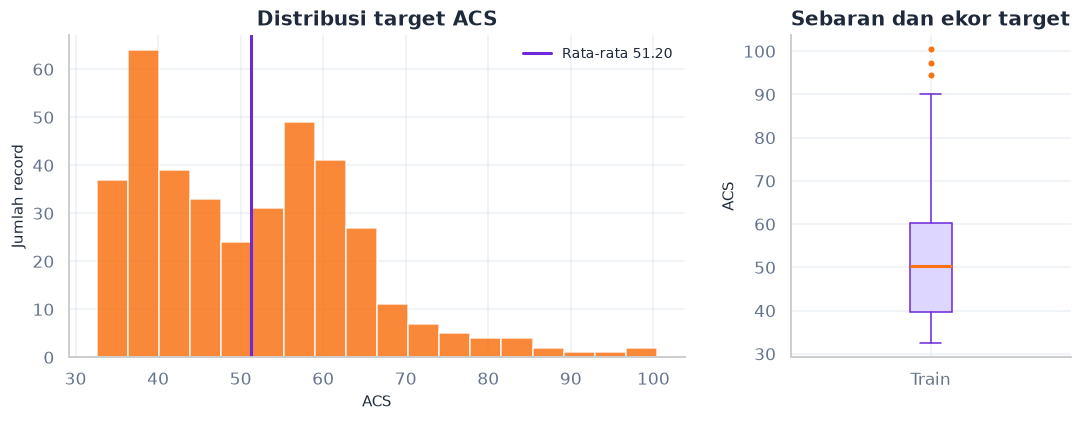

In [5]:
y = train.target.to_numpy(float)
target_summary = train.target.describe(percentiles=[.05,.25,.5,.75,.95]).rename('Nilai').reset_index()
target_summary.columns = ['Statistik','Nilai']
display(styled(target_summary, 'Ringkasan ACS pada train', {'Nilai':'{:.4f}'}))

fig, axes = plt.subplots(1, 2, figsize=(10.3, 4.3), gridspec_kw={'width_ratios':[2.2,1]})
axes[0].hist(y, bins=18, color=ORANGE, alpha=.85, edgecolor='white')
axes[0].axvline(np.mean(y), color=PURPLE, linewidth=2, label=f'Rata-rata {np.mean(y):.2f}')
axes[0].set(title='Distribusi target ACS', xlabel='ACS', ylabel='Jumlah record')
axes[0].legend(frameon=False, fontsize=9)
axes[1].boxplot(y, orientation='vertical', patch_artist=True,
                boxprops={'facecolor':'#DDD6FE','edgecolor':PURPLE},
                medianprops={'color':ORANGE,'linewidth':2},
                whiskerprops={'color':PURPLE}, capprops={'color':PURPLE},
                flierprops={'marker':'o','markerfacecolor':ORANGE,'markeredgecolor':'white','markersize':5})
axes[1].set(title='Sebaran dan ekor target', ylabel='ACS', xticks=[1], xticklabels=['Train'])
fig.tight_layout(pad=2)
save_plot(fig, '01_distribusi_target.png')
show_note(f'Target memiliki median <b>{np.median(y):.2f}</b> dan rata-rata <b>{np.mean(y):.2f}</b>. '
          f'Sebanyak <b>{int((y >= 75).sum())}</b> record memiliki ACS ≥ 75. '
          'Kami meninjau kesalahan kelompok ini secara terpisah pada tahap evaluasi.')

## <font color="#F28C28"><b>Hubungan fitur dengan ACS</b></font>

Kami menggunakan **korelasi Pearson** untuk melihat apakah suatu fitur cenderung naik atau turun bersama ACS. Nilai positif berarti keduanya cenderung naik bersama, sedangkan nilai negatif berarti bergerak berlawanan.

Korelasi hanya menunjukkan **hubungan linear**, bukan sebab-akibat atau bukti bahwa suatu fitur paling penting bagi model.

### <font color="#F28C28"><b>2.3 · Mencari fitur yang paling berkorelasi dengan ACS</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Menghitung korelasi setiap fitur terhadap ACS pada data train.
2. Menampilkan **<font color="#F28C28">10 fitur</font>** dengan nilai korelasi absolut terbesar.
3. Membuat grafik batang: **oranye** untuk korelasi positif dan **ungu** untuk korelasi negatif.

**<font color="#F28C28">Hasil yang dilihat:</font>** tabel arah dan kekuatan korelasi, serta grafik `02_korelasi_target.png`.

**<font color="#F28C28">Catatan:</font>** peringkat korelasi ini hanya untuk **eksplorasi data**, bukan untuk membuang fitur. Semua 24 fitur tetap digunakan dalam pemodelan.

Fitur,Korelasi Pearson,Nilai absolut
feature_09,+0.3911,0.3911
feature_15,-0.3756,0.3756
feature_12,-0.3716,0.3716
feature_17,+0.3518,0.3518
feature_13,+0.3476,0.3476
feature_07,-0.3316,0.3316
feature_03,-0.2594,0.2594
feature_23,+0.2482,0.2482
feature_20,-0.2417,0.2417
feature_24,+0.2260,0.2260


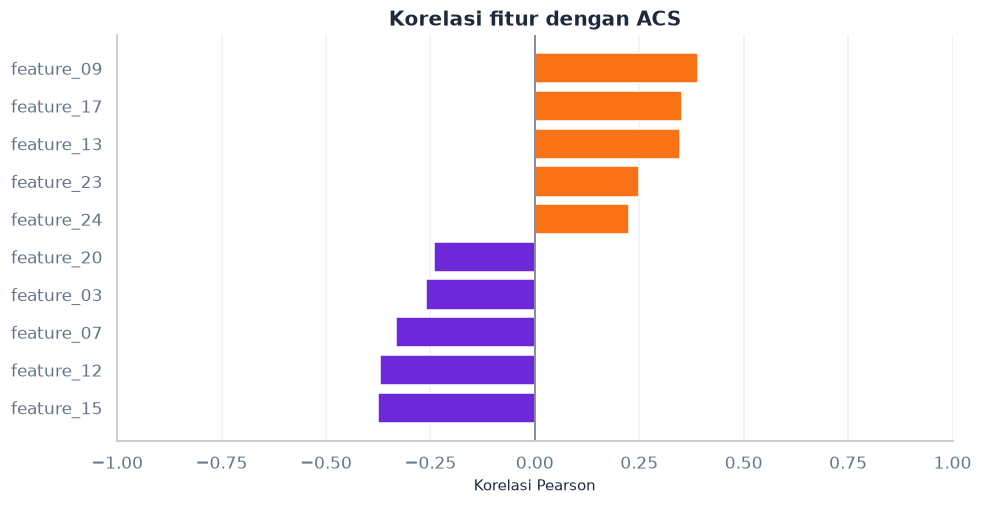

In [6]:
correlations = train[FEATURES].corrwith(train.target)
ranked_features = correlations.abs().sort_values(ascending=False).index
top_features = list(ranked_features[:10])
top_correlations = pd.DataFrame({'Fitur':top_features,
                                 'Korelasi Pearson':correlations.loc[top_features].to_numpy(),
                                 'Nilai absolut':correlations.loc[top_features].abs().to_numpy()})
display(styled(top_correlations, 'Sepuluh korelasi marginal terbesar',
               {'Korelasi Pearson':'{:+.4f}','Nilai absolut':'{:.4f}'}))
ordered = correlations.loc[top_features].sort_values()
fig, ax = plt.subplots(figsize=(9.8, 4.8))
ax.barh(ordered.index, ordered.to_numpy(), color=[PURPLE if v < 0 else ORANGE for v in ordered])
ax.axvline(0, color=GRAY, linewidth=1)
ax.set(title='Korelasi fitur dengan ACS', xlabel='Korelasi Pearson', xlim=(-1,1))
ax.grid(axis='y', visible=False)
save_plot(fig, '02_korelasi_target.png')

## <font color="#F28C28"><b>Hubungan antarfitur dan PCA</b></font>

Sebagian fitur mungkin memuat informasi yang mirip. Kami menggunakan **heatmap korelasi** untuk melihat keterkaitannya, lalu **PCA (Principal Component Analysis)** untuk memahami apakah 24 fitur dapat dirangkum menjadi lebih sedikit komponen.

PCA merangkum variasi data, **bukan langsung menunjukkan kemampuan memprediksi ACS**.

### <font color="#F28C28"><b>2.4 · Memeriksa korelasi fitur dan hasil PCA</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Membuat heatmap korelasi untuk seluruh pasangan 24 fitur.
2. Menyetarakan skala fitur dengan `StandardScaler`, lalu menjalankan PCA untuk eksplorasi.
3. Membuat grafik variasi kumulatif dan mencari jumlah komponen yang mencapai **90%** serta **95%** variasi.

**<font color="#F28C28">Hasil yang dilihat:</font>** grafik `03_korelasi_fitur.png` dan `04_variansi_pca.png`. Pada hasil yang tersedia, **4 komponen pertama menjelaskan sekitar 91,3% variasi**, sedangkan **6 komponen mencapai 95%**.

**<font color="#F28C28">Catatan:</font>** komponen dengan variasi kecil belum tentu tidak berguna untuk prediksi. Karena itu, model tetap memakai konfigurasi PCA **12, 16, dan 20 komponen** sesuai pipeline.

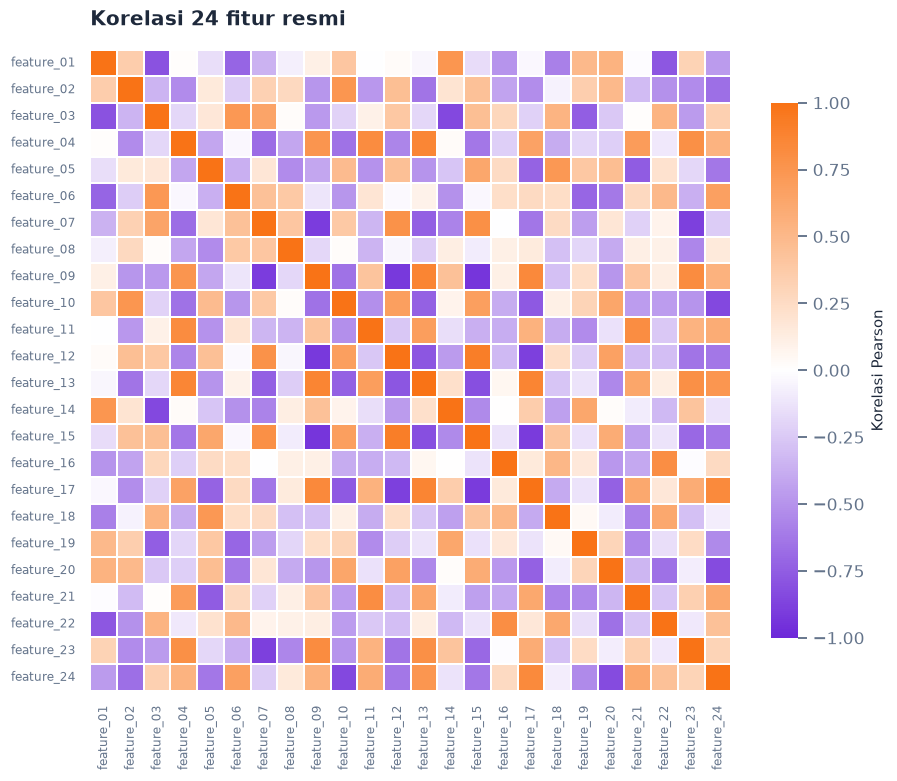

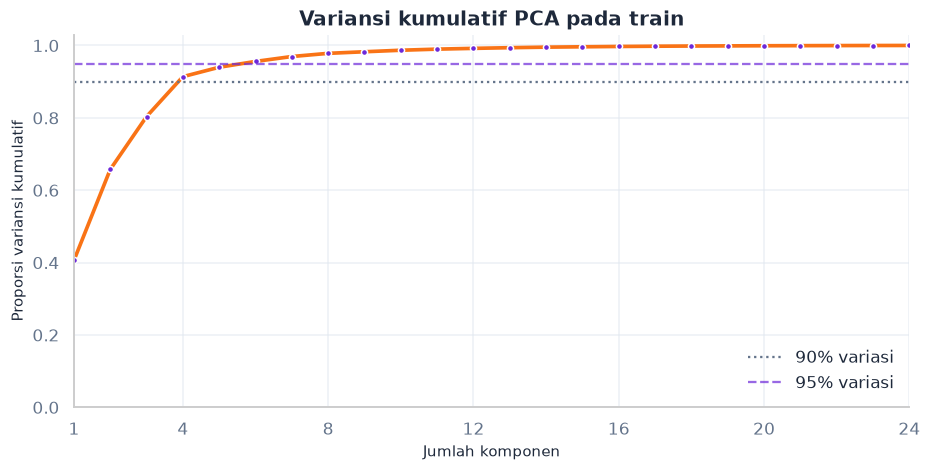

In [7]:
feature_corr = train[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9.4, 8.1))
sns.heatmap(feature_corr, vmin=-1, vmax=1, center=0, cmap=DIVERGING,
            square=True, linewidths=.12, cbar_kws={'label':'Korelasi Pearson','shrink':.78}, ax=ax)
ax.set_title('Korelasi 24 fitur resmi', loc='left', pad=16)
ax.tick_params(axis='both', labelsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
save_plot(fig, '03_korelasi_fitur.png')

scaled_train = StandardScaler().fit_transform(train[FEATURES])
pca_eda = PCA(n_components=24, svd_solver='full').fit(scaled_train)
cumulative_variance = np.cumsum(pca_eda.explained_variance_ratio_)
n90 = int(np.searchsorted(cumulative_variance, .90) + 1)
n95 = int(np.searchsorted(cumulative_variance, .95) + 1)
fig, ax = plt.subplots(figsize=(9.8, 4.4))
ax.plot(np.arange(1,25), cumulative_variance, color=ORANGE, linewidth=2.4,
        marker='o', markersize=4, markerfacecolor=PURPLE, markeredgecolor='white')
ax.axhline(.90, color=GRAY, linestyle=':', label='90% variasi')
ax.axhline(.95, color=PURPLE, linestyle='--', alpha=.7, label='95% variasi')
ax.set(title='Variansi kumulatif PCA pada train', xlabel='Jumlah komponen',
       ylabel='Proporsi variansi kumulatif', xlim=(1,24), ylim=(0,1.03), xticks=[1,4,8,12,16,20,24])
ax.legend(frameon=False, loc='lower right')
save_plot(fig, '04_variansi_pca.png')
upper = feature_corr.to_numpy()[np.triu_indices(24, k=1)]
show_note(f'Empat komponen pertama menjelaskan <b>{cumulative_variance[3]:.1%}</b> variasi fitur. '
          f'Ambang 95% tercapai pada <b>{n95} komponen</b>. '
          f'Korelasi absolut antarfitur terbesar adalah <b>{np.abs(upper).max():.4f}</b>. '
          'Temuan ini mendukung pemeriksaan representasi PCA untuk model berbasis jarak.')

## <font color="#F28C28"><b>Perbandingan fitur train dan test</b></font>

Kami membandingkan sebaran **6 fitur terpilih** antara train dan test. Keduanya menggunakan standar skala dari train dan batas histogram yang sama agar perbandingannya adil.

Grafik membantu melihat perbedaan pola, tetapi kemiripan fitur **tidak menjamin** nilai ACS pada test akan sama dengan train.

### <font color="#F28C28"><b>2.5 · Membandingkan train–test dan menyimpan hasil eksplorasi</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Memilih enam fitur dengan korelasi absolut terbesar dari eksplorasi sebelumnya.
2. Mengubah skala train dan test menggunakan rata-rata serta simpangan baku **dari train**.
3. Membuat histogram pembanding dengan batas yang sama, lalu menyimpan ringkasan EDA ke file JSON.

**<font color="#F28C28">Hasil yang dilihat:</font>** grafik `05_distribusi_train_test.png` dan ringkasan `hasil/eda_summary.json`.

**<font color="#F28C28">Catatan:</font>** grafik hanya menampilkan 6 dari 24 fitur. Tidak ada target test yang dipakai dalam perbandingan ini.

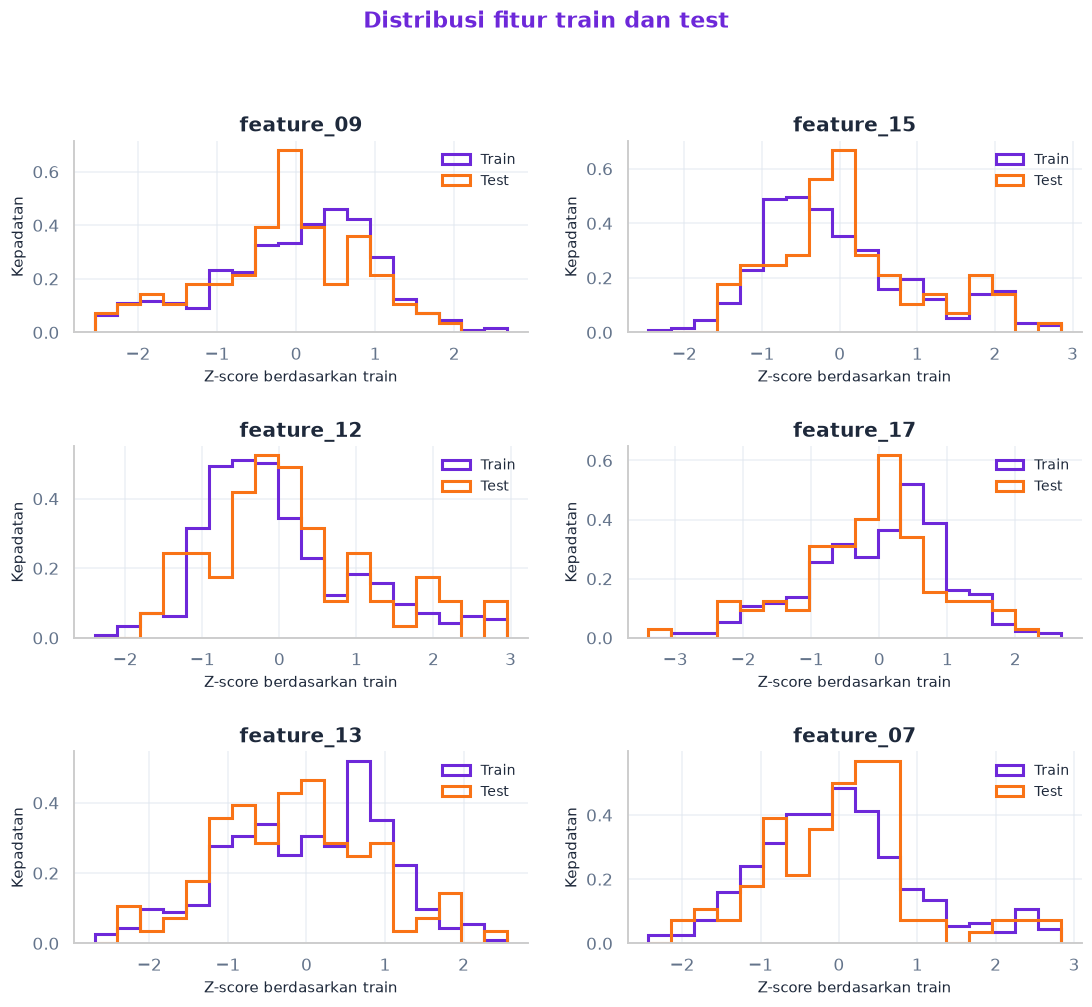

In [8]:
distribution_features = list(ranked_features[:6])
visual_scaler = StandardScaler().fit(train[FEATURES])
train_z = pd.DataFrame(visual_scaler.transform(train[FEATURES]), columns=FEATURES)
test_z = pd.DataFrame(visual_scaler.transform(test[FEATURES]), columns=FEATURES)
fig, axes = plt.subplots(3, 2, figsize=(10.4, 9.2))
for ax, feature in zip(axes.flat, distribution_features):
    values = np.concatenate([train_z[feature], test_z[feature]])
    bins = np.linspace(values.min(), values.max(), 19)
    ax.hist(train_z[feature], bins=bins, density=True, histtype='step', color=PURPLE, linewidth=2, label='Train')
    ax.hist(test_z[feature], bins=bins, density=True, histtype='step', color=ORANGE, linewidth=2, label='Test')
    ax.set(title=feature, xlabel='Z-score berdasarkan train', ylabel='Kepadatan')
    ax.legend(frameon=False, fontsize=9)
fig.suptitle('Distribusi fitur train dan test', color=PURPLE, fontweight='bold', y=1.01)
fig.tight_layout(pad=2)
save_plot(fig, '05_distribusi_train_test.png')

eda_summary = {
    'audit':audit.to_dict(orient='records'),
    'train_rows':len(train), 'test_rows':len(test), 'official_feature_count':len(FEATURES),
    'target':train.target.describe(percentiles=[.05,.25,.5,.75,.95]).to_dict(),
    'target_count_ge75':int((y >= 75).sum()),
    'feature_target_correlations':correlations.to_dict(),
    'max_abs_feature_correlation':float(np.abs(upper).max()),
    'pca_explained_variance_ratio':pca_eda.explained_variance_ratio_,
    'pca_cumulative_variance':cumulative_variance,
    'pca_components_90pct':n90, 'pca_components_95pct':n95,
}
save_json('eda_summary.json', eda_summary)

# <font color="#6A0DAD"><b>03 · Data Preparation</b></font>

Pada tahap ini, kami menyiapkan input untuk model: **24 fitur** dipisahkan dari `record_id` dan nilai `target`. Hasil audit menunjukkan data lengkap dan numerik, sehingga **<font color="#F28C28">tidak diperlukan pengisian nilai kosong (imputasi)</font>**.

Sebagian model memakai **<font color="#6A0DAD">standardisasi</font>** agar skala fitur lebih seimbang. Cabang PCA memakai standardisasi, PCA *whitening*, lalu standardisasi lagi. Pipeline memakai pendekatan **transduktif**: PCA boleh melihat fitur train, fitur validasi, dan fitur test **tanpa nilai ACS-nya**. Sementara itu, pelatihan model dan bobot yang membutuhkan target tetap menggunakan label bagian training saja.

Pendekatan ini sesuai alur kompetisi dengan kumpulan test yang tersedia. Untuk memprediksi data baru satu per satu di luar kompetisi, metode preprocessing ini perlu diuji kembali.

### <font color="#F28C28"><b>3.1 · Memisahkan fitur dan target</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Membuat `X` dari **24 fitur train**, `X_test` dari 24 fitur test, dan `y` dari nilai ACS train.
2. Memastikan jumlah kolom sesuai dan tidak ada `record_id` atau `target` di dalam matriks prediktor.
3. Menampilkan tabel yang menjelaskan perbedaan preprocessing pada cabang-cabang model.

**<font color="#F28C28">Hasil yang dilihat:</font>** ukuran `X` = **382 × 24**, `X_test` = **96 × 24**, dan `y` = **382 nilai target**.

**<font color="#F28C28">Catatan:</font>** tahap ini hanya menyiapkan data. Pembagian fold dan pelatihan sesungguhnya dilakukan pada tahap Modeling.

In [9]:
X = train.loc[:, FEATURES].to_numpy(dtype=float)
X_test = test.loc[:, FEATURES].to_numpy(dtype=float)
y = train.loc[:, 'target'].to_numpy(dtype=float)
assert X.shape == (len(train), 24) and X_test.shape == (len(test), 24)
assert 'record_id' not in FEATURES and 'target' not in FEATURES

preparation = pd.DataFrame([
    {'Komponen':'SVR standar / SVR berbobot', 'Representasi':'24 fitur + StandardScaler',
     'Data untuk fitting':'Training fold'},
    {'Komponen':'SVR dengan jarak korelasi', 'Representasi':'StandardScaler + bobot korelasi',
     'Data untuk fitting':'Fitur dan target training fold'},
    {'Komponen':'SVR pada PCA', 'Representasi':'StandardScaler → PCA whitening → StandardScaler',
     'Data untuk fitting':'Fitur train dan query/test tanpa label'},
    {'Komponen':'TabICL', 'Representasi':'24 fitur resmi',
     'Data untuk fitting':'Fitur dan target training fold'},
])
display(styled(preparation, 'Pemisahan transformasi dan pembelajaran terawasi'))

Komponen,Representasi,Data untuk fitting
SVR standar / SVR berbobot,24 fitur + StandardScaler,Training fold
SVR dengan jarak korelasi,StandardScaler + bobot korelasi,Fitur dan target training fold
SVR pada PCA,StandardScaler → PCA whitening → StandardScaler,Fitur train dan query/test tanpa label
TabICL,24 fitur resmi,Fitur dan target training fold


# <font color="#6A0DAD"><b>04 · Modeling</b></font>

Pada tahap ini, kami membandingkan **<font color="#F28C28">7 pendekatan</font>**: prediksi rata-rata, Ridge, Extra Trees, SVR standar, gabungan SVR, TabICL, dan gabungan akhir. Model sederhana digunakan sebagai **<font color="#6A0DAD">baseline</font>** (patokan awal), sehingga manfaat model yang lebih rumit bisa terlihat.

- **SVR:** mencari pola hubungan yang tidak harus berbentuk garis lurus. Beberapa cabang SVR memakai bobot target tinggi, jarak berbasis korelasi, atau PCA.
- **TabICL:** model *pretrained* umum yang mempelajari konteks dari data train berlabel, sesuai [dokumentasi pengembang](https://github.com/soda-inria/tabicl#pre-training).
- **Gabungan akhir:** menggabungkan **<font color="#F28C28">40% prediksi gabungan SVR</font>** dan **<font color="#F28C28">60% prediksi TabICL</font>**.

Pada salah satu SVR, record training dengan ACS ≥ 75 mendapat bobot pelatihan **1,5** agar lebih diperhatikan. Bobot ini **tidak mengubah cara menghitung RMSE**: semua record validasi tetap dihitung setara. Konfigurasi model ditetapkan sebelum evaluasi pada notebook ini.

### <font color="#F28C28"><b>4.1 · Memeriksa konfigurasi dan bobot model</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Menampilkan model pembanding dan rincian **5 komponen dalam gabungan SVR**.
2. Mencatat pengaturan SVR (termasuk bobot ACS tinggi, korelasi, dan pilihan PCA **12, 16, serta 20 komponen**).
3. Menampilkan pengaturan TabICL: **16 estimator**, CPU, *seed* 2026, dan nama checkpoint.
4. Memastikan seluruh bobot akhir jika dijumlahkan menjadi **100%**.

**<font color="#F28C28">Hasil yang dilihat:</font>** tabel konfigurasi serta pembagian bobot: lima komponen SVR menyumbang total **40%**, dan TabICL **60%**.

**<font color="#F28C28">Catatan:</font>** sel ini hanya **menampilkan konfigurasi**. Proses pelatihan dan pengujian berlangsung pada sel validasi berikutnya.

In [10]:
configuration = pd.DataFrame([
    {'Komponen':'SVR berbobot target tinggi', 'Konfigurasi':'RBF; C=100; gamma=0,08; epsilon=0,1',
     'Bobot dalam SVR':SVR_WEIGHTS['weighted_svr'], 'Bobot akhir':.4*SVR_WEIGHTS['weighted_svr']},
    {'Komponen':'SVR jarak korelasi', 'Konfigurasi':'RBF; C=100; gamma=0,08; floor=0,6; power=2',
     'Bobot dalam SVR':SVR_WEIGHTS['correlation_svr'], 'Bobot akhir':.4*SVR_WEIGHTS['correlation_svr']},
    {'Komponen':'SVR PCA 12', 'Konfigurasi':'Whitening; C=100; gamma=scale; epsilon=0,1',
     'Bobot dalam SVR':SVR_WEIGHTS['pca12_svr'], 'Bobot akhir':.4*SVR_WEIGHTS['pca12_svr']},
    {'Komponen':'SVR PCA 16', 'Konfigurasi':'Whitening; C=300; gamma=0,08; epsilon=0,1',
     'Bobot dalam SVR':SVR_WEIGHTS['pca16_svr'], 'Bobot akhir':.4*SVR_WEIGHTS['pca16_svr']},
    {'Komponen':'SVR PCA 20', 'Konfigurasi':'Whitening; C=100; gamma=0,04; epsilon=0,1',
     'Bobot dalam SVR':SVR_WEIGHTS['pca20_svr'], 'Bobot akhir':.4*SVR_WEIGHTS['pca20_svr']},
    {'Komponen':'TabICL', 'Konfigurasi':'16 estimator; CPU; random_state=2026',
     'Bobot dalam SVR':np.nan, 'Bobot akhir':FINAL_WEIGHTS['tabicl']},
])
assert np.isclose(configuration['Bobot akhir'].sum(), 1.)
display(styled(configuration, 'Konfigurasi dan kontribusi komponen',
               {'Bobot dalam SVR':'{:.0%}','Bobot akhir':'{:.1%}'}))
print('Checkpoint TabICL:', CHECKPOINT)

baselines = pd.DataFrame([
    {'Model':'Rata-rata target', 'Konfigurasi':'DummyRegressor(strategy="mean")'},
    {'Model':'Ridge', 'Konfigurasi':'StandardScaler; alpha=10'},
    {'Model':'Extra Trees', 'Konfigurasi':'400 pohon; min_samples_leaf=2; random_state=2026'},
    {'Model':'SVR standar', 'Konfigurasi':'StandardScaler; RBF; C=100; gamma=0,08; epsilon=0,1'},
])
display(styled(baselines, 'Model pembanding'))

Komponen,Konfigurasi,Bobot dalam SVR,Bobot akhir
SVR berbobot target tinggi,"RBF; C=100; gamma=0,08; epsilon=0,1",18%,7.2%
SVR jarak korelasi,"RBF; C=100; gamma=0,08; floor=0,6; power=2",20%,8.0%
SVR PCA 12,"Whitening; C=100; gamma=scale; epsilon=0,1",27%,10.8%
SVR PCA 16,"Whitening; C=300; gamma=0,08; epsilon=0,1",18%,7.2%
SVR PCA 20,"Whitening; C=100; gamma=0,04; epsilon=0,1",17%,6.8%
TabICL,16 estimator; CPU; random_state=2026,—,60.0%


Checkpoint TabICL: tabicl-regressor-v2-20260212.ckpt


Model,Konfigurasi
Rata-rata target,"DummyRegressor(strategy=""mean"")"
Ridge,StandardScaler; alpha=10
Extra Trees,400 pohon; min_samples_leaf=2; random_state=2026
SVR standar,"StandardScaler; RBF; C=100; gamma=0,08; epsilon=0,1"


## <font color="#F28C28"><b>Validasi silang dengan 5-fold</b></font>

Agar penilaian tidak bergantung pada satu pembagian data, kami memakai **KFold sebanyak 5 bagian** dengan pengacakan dan *seed* `314159`.

Pada setiap putaran, model belajar dari **4 bagian** dan diuji pada **1 bagian yang ditahan**. Setelah lima putaran, setiap record train memiliki satu prediksi saat record tersebut tidak digunakan sebagai data pelatihan. Prediksi ini disebut **out-of-fold (OOF)**.

### <font color="#F28C28"><b>4.2 · Menjalankan pelatihan dan validasi model</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Menjalankan fungsi `evaluate_models` untuk membagi train menjadi **5 fold**.
2. Melatih baseline, Ridge, Extra Trees, SVR, dan TabICL pada bagian training tiap fold.
3. Membuat prediksi untuk bagian validasi, lalu menyimpan prediksi OOF setiap model.
4. Menggabungkan prediksi SVR dan TabICL dengan bobot yang sudah ditentukan; kemudian mencatat waktu eksekusi.

**<font color="#F28C28">Hasil yang dilihat:</font>** progres Fold 1/5 hingga 5/5, hasil evaluasi 7 model, serta **382 prediksi OOF** untuk masing-masing model.

**Catatan penting:** label pada bagian validasi **tidak dipakai untuk melatih model**. Khusus PCA, fitur validasi dan test dapat dipakai tanpa label dalam transformasi transduktif. Dengan demikian, nilai ACS pada bagian yang ditahan baru dipakai **setelah prediksi dibuat**, untuk menghitung kesalahan.

In [11]:
VALIDATION_SEED, N_FOLDS = 314159, 5
started = time.perf_counter()
evaluation = evaluate_models(train, test, seed=VALIDATION_SEED, folds=N_FOLDS)
evaluation_seconds = time.perf_counter() - started
metrics = evaluation['metrics'].copy()
fold_metrics = evaluation['fold_metrics'].copy()
oof = evaluation['oof_predictions']
assert all(len(values) == len(train) and np.isfinite(values).all() for values in oof.values())
print(f'Evaluasi selesai dalam {evaluation_seconds/60:.2f} menit.')

Fold 1/5: final RMSE=7.829276


Fold 2/5: final RMSE=7.816522


Fold 3/5: final RMSE=6.110027


Fold 4/5: final RMSE=7.960952


Fold 5/5: final RMSE=8.190725


Evaluasi selesai dalam 1.73 menit.

# <font color="#6A0DAD"><b>05 · Evaluation</b></font>

Pada tahap evaluasi, kami menilai prediksi **<font color="#6A0DAD">OOF</font>** dengan dua ukuran:

- **RMSE:** ukuran utama kompetisi; lebih sensitif terhadap kesalahan besar.
- **MAE:** rata-rata selisih absolut antara prediksi dan nilai sebenarnya.

Kami juga memeriksa perbedaan hasil di tiap fold dan kelompok ACS. **<font color="#F28C28">RMSE OOF keseluruhan</font>** bisa berbeda dari rata-rata RMSE per fold karena cara penghitungannya berbeda. Hasil validasi ini bukan jaminan skor leaderboard.

### <font color="#F28C28"><b>5.1 · Membandingkan hasil seluruh model</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>** menampilkan RMSE dan MAE OOF untuk ketujuh model, membuat grafik perbandingan RMSE, serta menghitung perbaikan relatif terhadap baseline prediksi rata-rata.

**<font color="#F28C28">Hasil yang dilihat:</font>** pada output yang tersimpan, **<font color="#6A0DAD">gabungan akhir</font>** mendapat **<font color="#F28C28">RMSE 7,6194</font>** dan **MAE 5,1723**. Baseline memiliki RMSE **<font color="#F28C28">12,9442</font>**, sehingga RMSE gabungan akhir turun sekitar **41,1%**. Grafik disimpan sebagai `06_perbandingan_model.png`.

**<font color="#F28C28">Catatan:</font>** model terbaik di sini dipilih berdasarkan **RMSE**, bukan MAE atau nilai leaderboard. Hasil ini berasal dari validasi lokal menggunakan konfigurasi yang sudah ditetapkan.

Model,RMSE OOF,MAE OOF,Rata-rata RMSE fold,SD RMSE fold
Gabungan akhir,7.6194,5.1723,7.5815,0.8362
Gabungan SVR,7.7741,5.5493,7.7526,0.6130
TabICL,7.8336,5.1578,7.7721,1.0929
SVR standar,8.8199,6.1850,8.7951,0.7025
Extra Trees,8.9644,6.4936,8.9470,0.5906
Ridge,11.2344,8.5655,11.2322,0.2424
Rata-rata target,12.9442,10.8052,12.9319,0.5834


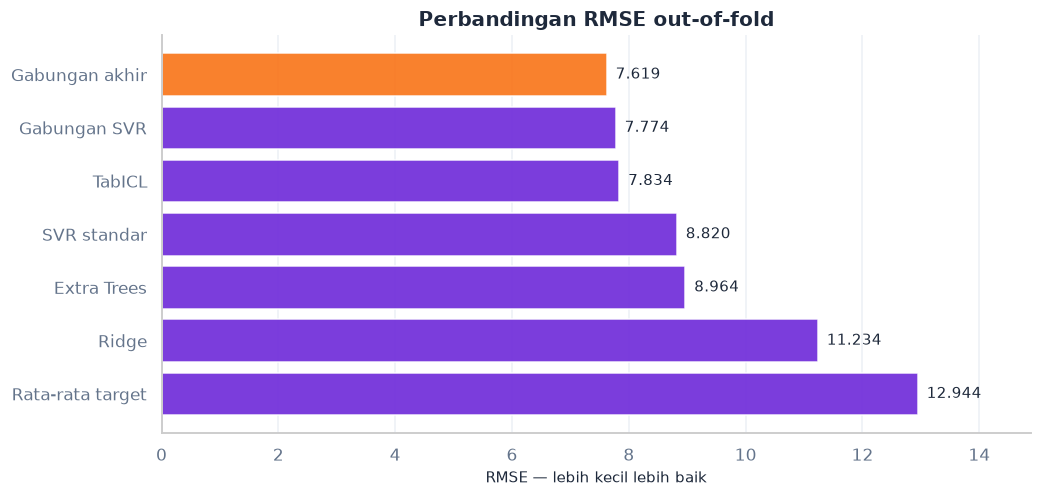

In [12]:
MODEL_LABELS = {
    'mean_baseline':'Rata-rata target', 'ridge':'Ridge', 'extra_trees':'Extra Trees',
    'scaled_svr':'SVR standar', 'svr_ensemble':'Gabungan SVR',
    'tabicl':'TabICL', 'final_ensemble':'Gabungan akhir',
}
metric_table = metrics.rename(columns={'model':'Model','rmse':'RMSE OOF','mae':'MAE OOF',
                                        'mean_fold_rmse':'Rata-rata RMSE fold','sd_fold_rmse':'SD RMSE fold'})
metric_table['Model'] = metric_table.Model.map(MODEL_LABELS)
comparison_style = styled(metric_table, 'Perbandingan model pada validasi lima fold',
                          {column:'{:.4f}' for column in metric_table if column != 'Model'})
comparison_style = comparison_style.apply(
    lambda row: ['background-color:#FFF7ED;font-weight:600;color:#1E293B'] * len(row)
    if row['Model'] == 'Gabungan akhir' else [''] * len(row), axis=1)
display(comparison_style)
fig, ax = plt.subplots(figsize=(10.2, 4.7))
colors = [ORANGE if name == 'final_ensemble' else PURPLE for name in metrics.model]
bars = ax.barh([MODEL_LABELS[name] for name in metrics.model], metrics.rmse, color=colors, alpha=.9)
ax.invert_yaxis()
ax.set(title='Perbandingan RMSE out-of-fold', xlabel='RMSE — lebih kecil lebih baik')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, metrics.rmse.max()*1.15)
for bar, value in zip(bars, metrics.rmse):
    ax.text(value + metrics.rmse.max()*.012, bar.get_y()+bar.get_height()/2,
            f'{value:.3f}', va='center', fontsize=10, color=INK)
save_plot(fig, '06_perbandingan_model.png')

final_metrics = metrics.set_index('model').loc['final_ensemble']
baseline_rmse = float(metrics.set_index('model').loc['mean_baseline','rmse'])
relative_improvement = 1 - float(final_metrics.rmse)/baseline_rmse
final_rank = int(np.flatnonzero(metrics.model.to_numpy() == 'final_ensemble')[0]+1)
show_note(f'Gabungan akhir menghasilkan <b>RMSE OOF {final_metrics.rmse:.4f}</b> dan '
          f'<b>MAE OOF {final_metrics.mae:.4f}</b>. RMSE turun <b>{relative_improvement:.1%}</b> '
          f'dibanding prediksi rata-rata target. Dalam evaluasi ini, gabungan akhir berada pada '
          f'urutan <b>{final_rank} dari {len(metrics)} model</b> berdasarkan RMSE OOF.')

TabICL memiliki **MAE sedikit lebih kecil** daripada gabungan akhir, tetapi **RMSE gabungan akhir lebih baik**. Kami memilih gabungan akhir karena kompetisi memakai RMSE sebagai ukuran utama.

## <font color="#F28C28"><b>Apakah hasilnya stabil di setiap fold?</b></font>

Satu nilai RMSE keseluruhan belum menunjukkan apakah model bekerja sama baiknya pada tiap bagian data. Karena itu, kami juga membandingkan hasil gabungan SVR, TabICL, dan gabungan akhir pada **lima fold yang sama**.

### <font color="#F28C28"><b>5.2 · Membandingkan RMSE pada setiap fold</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>** membuat tabel yang berisi jumlah record training dan validasi serta RMSE **gabungan SVR, TabICL, dan gabungan akhir** untuk setiap fold.

**<font color="#F28C28">Hasil yang dilihat:</font>** tiap fold memiliki **305–306 record training** dan **76–77 record validasi**. Nilai RMSE dapat naik atau turun karena record yang diuji berbeda.

**<font color="#F28C28">Catatan:</font>** model tidak harus menang di semua fold untuk menjadi yang terbaik secara keseluruhan. Karena itu, keputusan diambil dari **seluruh hasil OOF**, bukan hanya fold dengan nilai terbaik.

In [13]:
main_models = ['svr_ensemble','tabicl','final_ensemble']
fold_table = fold_metrics[fold_metrics.model.isin(main_models)].pivot(index='fold', columns='model', values='rmse')
counts = fold_metrics[fold_metrics.model == 'final_ensemble'].set_index('fold')[['n_train','n_validation']]
fold_table = counts.join(fold_table).reset_index().rename(columns={
    'fold':'Fold','n_train':'Record training','n_validation':'Record validasi',
    'svr_ensemble':'RMSE gabungan SVR','tabicl':'RMSE TabICL','final_ensemble':'RMSE gabungan akhir'})
fold_table = fold_table[['Fold','Record training','Record validasi','RMSE gabungan SVR','RMSE TabICL','RMSE gabungan akhir']]
display(styled(fold_table, 'Hasil komponen utama pada setiap fold',
               {column:'{:.4f}' for column in fold_table if column.startswith('RMSE')}))

Fold,Record training,Record validasi,RMSE gabungan SVR,RMSE TabICL,RMSE gabungan akhir
1,305,77,8.1940,7.8450,7.8293
2,305,77,8.1423,7.9244,7.8165
3,306,76,6.7266,5.9880,6.1100
4,306,76,8.0561,8.1321,7.9610
5,306,76,7.6440,8.9708,8.1907


## <font color="#F28C28"><b>Prediksi OOF dan residual</b></font>

Kami membandingkan **nilai ACS aktual dengan prediksi**. Titik yang dekat garis diagonal berarti prediksinya mendekati nilai sebenarnya.

Selisih **residual = prediksi − aktual**. Residual **positif** berarti prediksi terlalu tinggi, sedangkan residual **negatif** berarti prediksi terlalu rendah.

### <font color="#F28C28"><b>5.3 · Melihat pola kesalahan prediksi</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Membuat grafik nilai aktual vs prediksi OOF, dengan penanda khusus untuk **<font color="#F28C28">ACS ≥ 75</font>**.
2. Membuat grafik residual dan histogramnya untuk mencari pola kesalahan.
3. Menghitung **R²** sebagai informasi tambahan dan rata-rata residual. Grafik disimpan sebagai `07_prediksi_oof.png` dan `08_diagnostik_residual.png`.

**<font color="#F28C28">Hasil yang dilihat:</font>** titik yang jauh dari garis diagonal menunjukkan prediksi meleset. Pada hasil tersimpan, **R² OOF sekitar 0,6505** dan rata-rata residual **+0,3663**.

**<font color="#F28C28">Catatan:</font>** R² bukan persentase akurasi. Seluruh grafik ini memakai target train dan prediksi OOF, **bukan target test**.

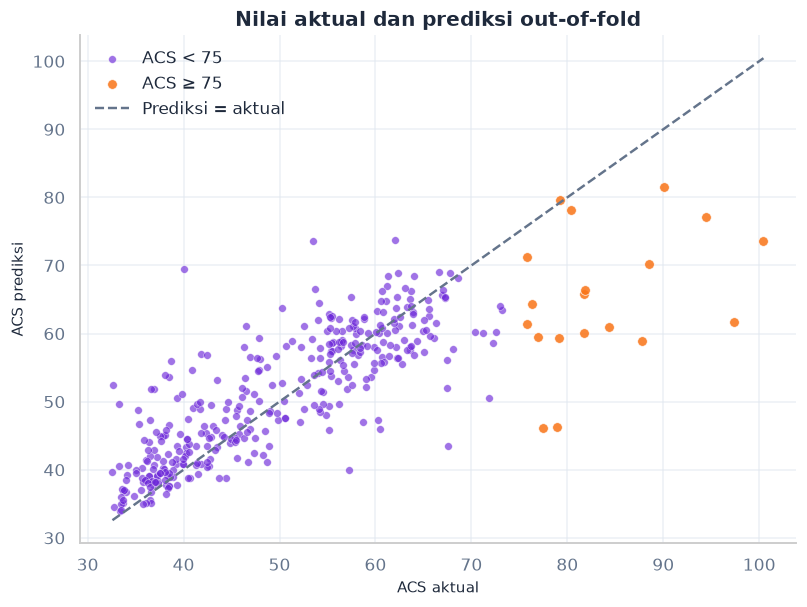

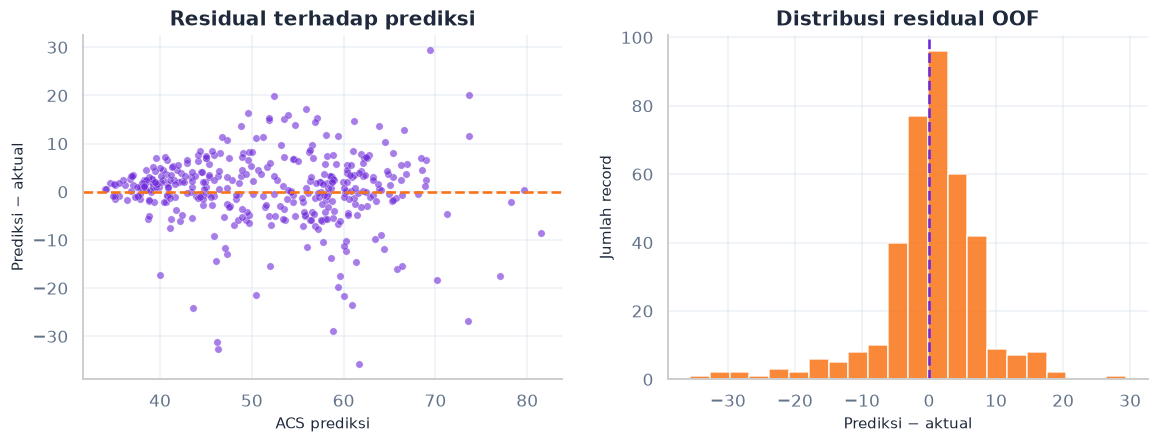

R² OOF: 0.6505; rata-rata residual: +0.3663


In [14]:
final_oof = np.asarray(oof['final_ensemble'], dtype=float)
residual = final_oof - y
low, high = min(y.min(),final_oof.min()), max(y.max(),final_oof.max())
fig, ax = plt.subplots(figsize=(8.4, 6.0))
regular, upper_target = y < 75, y >= 75
ax.scatter(y[regular], final_oof[regular], s=25, alpha=.65, color=PURPLE, edgecolors='white', linewidths=.35, label='ACS < 75')
ax.scatter(y[upper_target], final_oof[upper_target], s=40, alpha=.85, color=ORANGE, edgecolors='white', linewidths=.5, label='ACS ≥ 75')
ax.plot([low,high], [low,high], linestyle='--', color=GRAY, linewidth=1.6, label='Prediksi = aktual')
ax.set(title='Nilai aktual dan prediksi out-of-fold', xlabel='ACS aktual', ylabel='ACS prediksi')
ax.legend(frameon=False)
save_plot(fig, '07_prediksi_oof.png')

fig, axes = plt.subplots(1,2,figsize=(11.0,4.5))
axes[0].scatter(final_oof, residual, s=23, color=PURPLE, alpha=.6, edgecolors='white', linewidths=.3)
axes[0].axhline(0, color=ORANGE, linestyle='--', linewidth=1.7)
axes[0].set(title='Residual terhadap prediksi', xlabel='ACS prediksi', ylabel='Prediksi − aktual')
axes[1].hist(residual, bins=22, color=ORANGE, alpha=.85, edgecolor='white')
axes[1].axvline(0, color=PURPLE, linestyle='--', linewidth=1.7)
axes[1].set(title='Distribusi residual OOF', xlabel='Prediksi − aktual', ylabel='Jumlah record')
fig.tight_layout(pad=2)
save_plot(fig, '08_diagnostik_residual.png')
print(f'R² OOF: {r2_score(y,final_oof):.4f}; rata-rata residual: {residual.mean():+.4f}')

## <font color="#F28C28"><b>Kesalahan pada tiap kelompok ACS</b></font>

Kami membagi nilai ACS aktual menjadi empat rentang: **di bawah 45**, **45–kurang dari 60**, **60–kurang dari 75**, dan **75 ke atas**. Pembagian ini hanya untuk memahami di mana model sering salah, bukan kategori resmi kompetisi.

Selain RMSE dan MAE, kami melihat **bias rata-rata**. Bias negatif menunjukkan model cenderung memprediksi terlalu rendah pada kelompok tersebut.

### <font color="#F28C28"><b>5.4 · Mengukur kesalahan per rentang ACS</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>** menghitung jumlah record, RMSE, MAE, dan bias untuk keempat rentang ACS. Hasil validasi juga disimpan ke `hasil/metrics_cv.json`, `hasil/validation_summary.json`, dan `hasil/oof_predictions.npz`.

**<font color="#F28C28">Hasil yang dilihat:</font>** jumlah record per rentang berturut-turut **148, 137, 78, dan 19**. Kelompok **<font color="#F28C28">ACS ≥ 75</font>** memiliki RMSE paling besar, sekitar **20,73**, dengan bias sekitar **−18,22**. Ini berarti nilai ACS tinggi masih sering **diprediksi terlalu rendah**.

**<font color="#F28C28">Catatan:</font>** kelompok ACS tinggi hanya memiliki **19 record**, sehingga hasilnya perlu dibaca hati-hati. Pembagian kelompok ini berdasarkan target train dan **tidak dipakai untuk mengelompokkan test** yang targetnya tidak tersedia.

In [15]:
band_labels = ['< 45','45–< 60','60–< 75','≥ 75']
bands = pd.cut(y, bins=[-np.inf,45,60,75,np.inf], right=False, labels=band_labels)
band_rows = []
for label in band_labels:
    mask = np.asarray(bands == label)
    band_rows.append({'Rentang ACS aktual':label,'Record':int(mask.sum()),
                      'RMSE':float(np.sqrt(np.mean(residual[mask]**2))) if mask.any() else None,
                      'MAE':float(np.mean(np.abs(residual[mask]))) if mask.any() else None,
                      'Bias prediksi−aktual':float(np.mean(residual[mask])) if mask.any() else None})
band_metrics = pd.DataFrame(band_rows)
display(styled(band_metrics, 'Performa OOF menurut rentang target',
               {'RMSE':'{:.4f}','MAE':'{:.4f}','Bias prediksi−aktual':'{:+.4f}'}))
worst_band = band_metrics.loc[band_metrics.RMSE.idxmax()]
show_note(f'Rentang dengan RMSE terbesar pada evaluasi ini adalah <b>{worst_band["Rentang ACS aktual"]}</b> '
          f'dengan <b>{int(worst_band.Record)} record</b>. '
          'Kami membaca hasil kelompok tersebut bersama ukuran sampelnya, bukan sebagai kepastian performa pada test.')
high_band = band_metrics[band_metrics['Rentang ACS aktual'] == '≥ 75'].iloc[0]
show_note(f'Pada ACS ≥ 75, RMSE mencapai <b>{high_band.RMSE:.2f}</b> dan '
          f'rata-rata residual adalah <b>{high_band["Bias prediksi−aktual"]:+.2f}</b>. '
          'Model cenderung memprediksi terlalu rendah pada kelompok ini. '
          'Walaupun komponen SVR memberi perhatian tambahan pada target tinggi, '
          'hasil OOF menunjukkan bahwa masalah tersebut belum teratasi.')

evaluation_payload = {
    'metric':'RMSE', 'validation':{'method':'KFold','folds':N_FOLDS,'shuffle':True,'seed':VALIDATION_SEED,
                                 'preprocessing':'transductive PCA on train and unlabeled official test features',
                                 'supervised_targets':'training portion of each fold only'},
    'model_metrics':metrics.to_dict(orient='records'),
    'fold_metrics':fold_metrics.to_dict(orient='records'),
    'target_band_metrics':band_metrics.to_dict(orient='records'),
    'final_oof_r2':float(r2_score(y,final_oof)),
    'final_mean_residual':float(residual.mean()),
    'final_residual_std':float(residual.std(ddof=1)),
    'evaluation_seconds':float(evaluation_seconds),
    'checkpoint':CHECKPOINT, 'svr_weights':SVR_WEIGHTS, 'final_weights':FINAL_WEIGHTS,
    'packages':package_versions,
}
save_json('metrics_cv.json', evaluation_payload)
canonical_bands = [{'band':row['Rentang ACS aktual'], 'n':row['Record'],
                    'rmse':row['RMSE'], 'mae':row['MAE'], 'bias':row['Bias prediksi−aktual']}
                   for row in band_rows]
report_summary = dict(evaluation_payload)
report_summary['metrics'] = metrics.to_dict(orient='records')
report_summary['target_bands'] = canonical_bands
report_summary['data_summary'] = {
    'n_train':len(train), 'n_test':len(test), 'n_features':len(FEATURES),
    'audit':audit.to_dict(orient='records'), 'target_statistics':eda_summary['target'],
    'pca_4_cumulative_variance':float(cumulative_variance[3]),
    'pca_components_95pct':n95,
    'max_abs_feature_correlation':float(np.abs(upper).max()),
}
save_json('validation_summary.json', report_summary)
fold_indices = np.zeros(len(train), dtype=int)
for fold, (_, validation_indices) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=VALIDATION_SEED).split(X),1):
    fold_indices[validation_indices] = fold
np.savez(RESULTS / 'oof_predictions.npz', target=y, fold_indices=fold_indices, **oof)

Rentang ACS aktual,Record,RMSE,MAE,Bias prediksi−aktual
< 45,148,6.3923,4.3988,+3.8920
45–< 60,137,5.5304,4.2422,+1.1799
60–< 75,78,6.9528,5.0879,-3.2257
≥ 75,19,20.7347,18.2500,-18.2169


## <font color="#F28C28"><b>Insight utama dari hasil analisis</b></font>

**<font color="#6A0DAD">1. Model sudah lebih baik daripada tebakan sederhana.</font>** Gabungan akhir menghasilkan RMSE lebih kecil dibanding baseline rata-rata ACS pada validasi 5-fold.

**<font color="#F28C28">2. Prediksi ACS tinggi masih menjadi kelemahan.</font>** Pada kelompok ACS ≥ 75, model cenderung memprediksi terlalu rendah. Pembobotan pada salah satu SVR belum sepenuhnya mengatasi hal ini, sehingga hasil pada kelompok tinggi perlu diperhatikan.

**<font color="#6A0DAD">3. Pola fitur bisa dipelajari, tetapi maknanya terbatas.</font>** PCA dan korelasi menunjukkan hubungan antarangka. Namun, karena fitur sudah dianonimkan, kami **tidak bisa menyimpulkan penyebab ekonomi atau kondisi wilayah tertentu**.

**<font color="#F28C28">4. Prediksi adalah perkiraan skor relatif, bukan harga dalam rupiah.</font>** Hasil model belum bisa langsung dipakai sebagai besaran anggaran atau keputusan operasional.

Ke depan, evaluasi bisa diperluas dengan pembagian data lain dan tambahan data berlabel **jika resmi disediakan**, terutama untuk memeriksa kelompok ACS tinggi.

# <font color="#6A0DAD"><b>06 · Deployment</b></font>

Dalam kompetisi ini, *deployment* berarti menyiapkan **<font color="#F28C28">prediksi ACS untuk seluruh 96 record test</font>** dan memastikan formatnya benar.

Model akhir dilatih kembali menggunakan **seluruh 382 record train berlabel**, dengan konfigurasi dan bobot yang sama. Hasilnya dibandingkan dengan `submission.csv` yang sudah dipilih. **Notebook tidak menimpa file submission tersebut.** Selisih kecil akibat pembulatan atau perhitungan numerik dicek dengan toleransi `0,0001`.

### <font color="#F28C28"><b>6.1 · Membuat ulang dan memeriksa submission</b></font>
**<font color="#6A0DAD">Yang dilakukan:</font>**

1. Menjalankan `predict_components` pada seluruh train dan test, lalu mengambil prediksi **<font color="#6A0DAD">gabungan akhir</font>**.
2. Memastikan file submission memiliki **96 baris**, kolom `record_id` dan `prediction`, ID sesuai test, serta angka prediksi yang valid.
3. Membandingkan prediksi hasil reproduksi dengan `submission.csv` **berdasarkan ID**, bukan posisi baris. Batas selisih yang diterima adalah `0,0001`.
4. Menyimpan ringkasan pemeriksaan, sidik isi berkas (**SHA-256**), dan komponen prediksi test.
5. Menampilkan tautan serta memulai unduhan `submission.csv` di Google Colab.

**<font color="#F28C28">Hasil yang dilihat:</font>** tabel audit submission, contoh **10 baris prediksi**, serta `hasil/reproduction_summary.json` dan `hasil/test_prediction_components.npz`. Pada output tersimpan, rentang prediksinya sekitar **33,8854–86,5210**.

**<font color="#F28C28">Catatan:</font>** pemeriksaan ini memastikan format dan konsistensi prediksi, **bukan membuktikan skor RMSE test**, karena nilai ACS test tidak tersedia.

In [16]:
final_started = time.perf_counter()
final_components = predict_components(train, test)
reproduced_prediction = final_components['final_ensemble']
reproduced = pd.DataFrame({'record_id':test.record_id, 'prediction':reproduced_prediction})
validate_submission(reproduced, test)

# Jika submission historis tersedia, lakukan pemeriksaan reproduksi yang sama.
# Jika tidak, simpan prediksi yang baru dibuat tanpa mengklaim sudah direproduksi.
submission_path = PROJECT / 'submission.csv'
ada_submission_lama = submission_path.is_file()
if ada_submission_lama:
    selected_submission = pd.read_csv(submission_path)
    validate_submission(selected_submission, test)
    selected_aligned = selected_submission.set_index('record_id').loc[test.record_id, 'prediction'].to_numpy(float)
    differences = np.abs(selected_aligned - reproduced_prediction)
    assert np.allclose(selected_aligned, reproduced_prediction, rtol=0, atol=1e-4), (
        f'Reproduksi berbeda dari submission terpilih; selisih maksimum {differences.max():.8f}'
    )
    print('Prediksi cocok dengan submission historis (toleransi absolut 1e-4).')
else:
    selected_submission = reproduced.copy()
    selected_submission.to_csv(submission_path, index=False)
    selected_aligned = reproduced_prediction.copy()
    differences = None
    print('Tidak ada submission lama; file submission.csv BARU dibuat dari model asli.')

submission_audit = pd.DataFrame([
    {'Pemeriksaan':'Jumlah prediksi','Hasil':len(selected_submission)},
    {'Pemeriksaan':'Kolom','Hasil':', '.join(selected_submission.columns)},
    {'Pemeriksaan':'ID unik','Hasil':selected_submission.record_id.nunique()},
    {'Pemeriksaan':'ID sesuai test','Hasil':str(set(selected_submission.record_id) == set(test.record_id))},
    {'Pemeriksaan':'Semua prediksi finite','Hasil':str(np.isfinite(selected_aligned).all())},
    {'Pemeriksaan':'Selisih reproduksi maksimum','Hasil':f'{differences.max():.10f}' if ada_submission_lama else 'Tidak dibandingkan (submission baru)'},
    {'Pemeriksaan':'Rentang prediksi','Hasil':f'{selected_aligned.min():.4f} – {selected_aligned.max():.4f}'},
])
display(styled(submission_audit, 'Validasi submission terpilih dan reproduksi'))
display(styled(selected_submission.head(10), 'Sepuluh baris awal submission', {'prediction':'{:.4f}'}))
print(f'Pelatihan akhir dan pemeriksaan selesai dalam {(time.perf_counter()-final_started)/60:.2f} menit.')

# Hanya hash file yang memang tersedia; file opsional tidak dipalsukan.
source_paths = [DATA/'train.csv', DATA/'test.csv', DATA/'data_dictionary.csv',
                PROJECT/'ketentuan/competition_rules.md', PROJECT/'submission.csv']
source_hashes = {str(path.relative_to(PROJECT)) if path.is_relative_to(PROJECT) else str(path):
                 hashlib.sha256(path.read_bytes()).hexdigest()
                 for path in source_paths if path is not None and path.is_file()}
save_json('reproduction_summary.json', {
    'records':len(reproduced), 'columns':list(reproduced.columns),
    'max_absolute_difference':float(differences.max()) if ada_submission_lama else None, 'tolerance_absolute':1e-4,
    'prediction_min':float(selected_aligned.min()), 'prediction_max':float(selected_aligned.max()),
    'prediction_mean':float(selected_aligned.mean()), 'all_predictions_finite':bool(np.isfinite(selected_aligned).all()),
    'source_sha256':source_hashes, 'embedded_pipeline_sha256':PIPELINE_SOURCE_SHA256,
    'execution_utc':datetime.now(timezone.utc).isoformat(),
})
np.savez(RESULTS / 'test_prediction_components.npz', **final_components)

print('Submission siap:', submission_path)
display(FileLink(str(submission_path), result_html_prefix='Klik untuk mengunduh: '))
if IN_COLAB:
    from google.colab import files as colab_files
    colab_files.download(str(submission_path))


Tidak ada submission lama; file submission.csv BARU dibuat dari model asli.


Pemeriksaan,Hasil
Jumlah prediksi,96
Kolom,"record_id, prediction"
ID unik,96
ID sesuai test,True
Semua prediksi finite,True
Selisih reproduksi maksimum,Tidak dibandingkan (submission baru)
Rentang prediksi,33.8854 – 86.5210


record_id,prediction
D0263,86.5210
D0280,75.9332
D0206,40.6144
D0133,40.0979
D0352,62.1206
D0339,77.5877
D0261,69.5484
D0409,73.0277
D0411,62.4267
D0144,61.9128


Pelatihan akhir dan pemeriksaan selesai dalam 0.34 menit.
Submission siap: .\submission.csv


.\submission.csv

## <font color="#F28C28"><b>Kesimpulan</b></font>

Kami memprediksi ACS dengan **<font color="#6A0DAD">24 fitur resmi</font>** melalui enam tahap CRISP-DM. Data diperiksa terlebih dahulu, beberapa model dibandingkan dengan **validasi 5-fold**, lalu gabungan **<font color="#F28C28">40% SVR dan 60% TabICL</font>** digunakan untuk menghasilkan prediksi test.

Pada validasi OOF yang tersimpan, gabungan akhir memperoleh **<font color="#F28C28">RMSE 7,6194</font>**, lebih kecil daripada baseline **<font color="#F28C28">12,9442</font>**. Namun, prediksi untuk **<font color="#F28C28">ACS ≥ 75</font>** masih sering terlalu rendah. Karena ACS dan fiturnya anonim, hasil ini tidak bisa diartikan sebagai harga dalam rupiah atau bukti sebab-akibat.

**<font color="#6A0DAD">Hasil akhir:</font>** 96 prediksi test diperiksa kesesuaian format, ID, nilai numerik, dan reproduksinya. Skor private leaderboard **tidak dihitung atau diklaim** di notebook ini.

## <font color="#F28C28"><b>Sumber dan berkas pendukung</b></font>

- **Data resmi:** [train](data/train.csv), [test](data/test.csv), dan [kamus data](data/data_dictionary.csv).
- **Aturan kompetisi:** [competition_rules.md](ketentuan/competition_rules.md) dan [Case Release](ketentuan/Case%20Release_DSC%20FIK%20FAIR%202026.pdf).
- **Metode:** [CRISP-DM](https://www.ibm.com/docs/en/spss-modeler/18.6.0?topic=dm-crisp-help-overview), [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html), dan [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- **TabICL:** [repositori](https://github.com/soda-inria/tabicl#pre-training), [model](https://huggingface.co/jingang/TabICL), dan [checkpoint regresi](https://huggingface.co/jingang/TabICL/blob/main/tabicl-regressor-v2-20260212.ckpt).
- **Kode model:** tertanam langsung di notebook dan dilengkapi SHA-256. Grafik tersimpan di `assets/` dan ringkasan numerik di `hasil/`.

Setelah seluruh sel selesai, gunakan tautan unduhan atau panel **Files** Colab untuk mengambil `submission.csv`. Simpan juga notebook hasil eksekusi melalui **File → Download → Download .ipynb** sebagai bukti reproduksi.